# Vérification d'une explication orale avec Qwen2.5-Omni-7

In [1]:
CHEMIN_PDF = "/kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf"     # ex. "/kaggle/input/mon-cours/cours.pdf"
CHEMIN_AUDIO = "/kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3"    # ex. "/kaggle/input/mon-cours/explication.mp3"

MODEL_ID = "Qwen/Qwen2.5-Omni-7B"

MODE_CHARGEMENT = "auto"        # "auto", "16bits", "8bits" ou "4bits"
RESERVE_ACTIVATIONS_GIO = 3.0   # mémoire laissée libre sur chaque GPU pour les calculs (activations, cache)

# --- Résolution des pages (1 token visuel = 28 x 28 pixels) ---
BUDGET_TOKENS_IMAGES = 14000    # budget total pour l'ensemble des pages
TOKENS_MAX_PAR_PAGE = 1280      # une diapositive 16:9 reste lisible (~1 300 x 730 px) ; moins de tokens image = l'audio pèse plus
TOKENS_MIN_PAR_PAGE = 640

# --- Texte du cours ---
AJOUTER_TEXTE_PDF = True        # donne aussi au modèle le texte de chaque page (extrait du PDF) : il recopie le cours au lieu de le déchiffrer
MAX_CARACTERES_TEXTE_PAGE = 3000

# --- Audio ---
NORMALISER_VOLUME = True        # remonte le volume de la version envoyée au modèle (crête à 0,9) ; l'original n'est jamais modifié

# --- Génération du rapport ---
MAX_NOUVEAUX_TOKENS = 2048      # écoute + vérification de chaque affirmation (~150 tokens par affirmation)
ECHANTILLONNAGE = False         # False = réponse déterministe (recommandé pour une évaluation)
AFFICHER_EN_DIRECT = True       # affiche l'analyse au fur et à mesure de sa génération

# --- Pages du PDF à analyser ---
# None = toutes les pages. Pour un long PDF, gardez seulement les pages dont parle l'audio,
# ex. "1-5" ou "3, 4, 7-9" : moins de pages = images plus lisibles et moins de mémoire.
PAGES_A_ANALYSER = "14-20"   # slides dont parle l'audio (le modèle a situé risque/incertitude en page 17)


# --- Évaluation des performances ---
TRANSCRIPTION_REFERENCE = None  # facultatif : ce que tu as réellement dit (texte) → taux d'erreur de mots de l'écoute (WER)
INTERVALLE_MESURE_S = 0.5       # fréquence des mesures GPU / CPU / RAM pendant l'exécution

# --- Comparaison avec Phi-4 (section 16) ---
DOSSIER_RESULTATS_AUTRE_MODELE = None   # dossier des résultats de Phi-4 (performance.json…) ; None = recherche automatique

DOSSIER_ENTREES = "/kaggle/input"                       # fichiers importés (lecture seule)
DOSSIER_TRAVAIL = "/kaggle/working/analyse_qwen_omni"   # images, audio préparé, résultats

In [2]:
import os, sys, shutil, subprocess, json, time, gc, math, re, hashlib, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # limite la fragmentation mémoire GPU
import torch

# Dossier de sortie (images des pages, audio préparé, résultats)
os.makedirs(DOSSIER_TRAVAIL, exist_ok=True)


def mesurer_memoire_libre(gpus):
    """Met à jour la mémoire libre/totale (en Gio) de chaque GPU de la liste."""
    for g in gpus:
        libre, total = torch.cuda.mem_get_info(g["index"])
        g["libre_gio"], g["total_gio"] = libre / 2**30, total / 2**30
    return gpus


def liberer_memoire():
    """Libère la mémoire GPU inutilisée (après une erreur ou avant un rechargement)."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def est_erreur_memoire(e):
    return isinstance(e, torch.cuda.OutOfMemoryError) or "out of memory" in str(e).lower()


# --- GPU : détection + test de calcul réel en FP16 ---
if not torch.cuda.is_available():
    raise RuntimeError("❌ Aucun GPU CUDA détecté. Settings → Accelerator → 'GPU T4 x2', puis relancez la session.")

GPU_UTILISABLES = []
for i in range(torch.cuda.device_count()):
    prop = torch.cuda.get_device_properties(i)
    try:
        a = torch.randn(512, 512, device=f"cuda:{i}", dtype=torch.float16)
        utilisable = bool(torch.isfinite((a @ a).float().sum()).item())
        del a
    except Exception:
        utilisable = False
    if utilisable:
        GPU_UTILISABLES.append({"index": i, "nom": prop.name, "bf16_natif": prop.major >= 8})

if not GPU_UTILISABLES:
    raise RuntimeError("❌ GPU détecté mais inutilisable avec cette version de PyTorch. "
                       "Choisissez 'GPU T4 x2' dans Settings → Accelerator.")

mesurer_memoire_libre(GPU_UTILISABLES)
torch.cuda.empty_cache()
for g in GPU_UTILISABLES:
    print(f"✅ GPU {g['index']} : {g['nom']} | {g['libre_gio']:.1f} / {g['total_gio']:.1f} Gio libres | "
          f"BF16 natif : {'oui' if g['bf16_natif'] else 'non → FP16'}")

✅ GPU 0 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 natif : non → FP16
✅ GPU 1 : Tesla T4 | 14.4 / 14.6 Gio libres | BF16 natif : non → FP16


## 3. Installation des bibliothèques

| Bibliothèque | Rôle |
|---|---|
| `transformers==5.24.0` | Classes `Qwen2_5OmniThinkerForConditionalGeneration` et `Qwen2_5OmniProcessor` |
| `accelerate==1.16.0` | Répartition automatique du modèle sur plusieurs GPU (`device_map`) |
| `qwen-omni-utils==0.0.9` (+ `audioread`) | Utilitaire officiel Qwen (`process_mm_info`) qui prépare images et audio |
| `pymupdf==2.1` | Lecture du PDF et rendu des pages en images |
| `soundfile==0.14.0` | Lecture des fichiers WAV et MP3 |
| `pillow` | Manipulation des images |
| `librosa` (dépendance de `qwen-omni-utils`), `matplotlib` | Rééchantillonnage audio en 16 kHz ; aperçu des pages |
| `nvidia-ml-py` | Lecture de l'utilisation, de la mémoire et de la puissance des GPU (évaluation) |
| `psutil` | Mesure du CPU et de la RAM (évaluation) |
| `pandas` | Tableaux de l'évaluation et de la comparaison |

In [3]:
import importlib.metadata as metadata

VERSIONS = {
    "transformers": "5.24.0",
    "accelerate": "1.16.0",
    "qwen-omni-utils": "0.0.9",
    "pymupdf": "2.1",
    "soundfile": "0.14.0",
}
TAILLE_THINKER_16BITS_GIO = 16.64   # 8,93 milliards de paramètres x 2 octets (calcul exact refait à l'étape 6)


def pip_installer(paquets, options=()):
    """Installe des paquets avec pip dans l'environnement du notebook."""
    commande = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *options, *paquets]
    print("pip install", " ".join(list(options) + list(paquets)))
    res = subprocess.run(commande, capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-2000:], res.stderr[-3000:])
        raise RuntimeError("❌ Échec de l'installation (vérifiez que Internet est activé : Settings → Internet → On).")


def fichiers_presents(dossier, extensions):
    if not os.path.isdir(dossier):
        return []
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(dossier) for f in fs if f.lower().endswith(extensions))


if "transformers" in sys.modules and sys.modules["transformers"].__version__ != VERSIONS["transformers"]:
    print("⚠️  Une autre version de transformers est déjà importée dans cette session : "
          "après l'installation, faites Run → Restart & clear cell outputs, puis relancez tout.")

t0 = time.time()
paquets = [f"{nom}=={version}" for nom, version in VERSIONS.items()]
paquets += ["audioread", "librosa", "pillow", "matplotlib"]   # audioread : dépendance manquante de qwen-omni-utils 0.0.9
paquets += ["pandas", "psutil", "nvidia-ml-py"]   # évaluation des performances : tableaux, CPU/RAM, GPU (utilisation, puissance)
pip_installer(paquets)

# bitsandbytes : seulement si la mémoire GPU libre ne suffit pas pour le mode 16 bits
capacite_gio = sum(max(0.0, g["libre_gio"] - RESERVE_ACTIVATIONS_GIO) for g in GPU_UTILISABLES)
BESOIN_QUANTIFICATION = MODE_CHARGEMENT in ("8bits", "4bits") or (
    MODE_CHARGEMENT == "auto" and capacite_gio < TAILLE_THINKER_16BITS_GIO * 1.03)
if BESOIN_QUANTIFICATION:
    print(f"Mémoire GPU disponible ({capacite_gio:.1f} Gio après marge) insuffisante pour le mode 16 bits "
          "→ installation de bitsandbytes (quantification 8 / 4 bits).")
    pip_installer(["bitsandbytes==0.50.2"])

DUREE_INSTALLATION_S = time.time() - t0
print(f"\nInstallation terminée en {DUREE_INSTALLATION_S:.0f} s. Versions installées :")
for nom in list(VERSIONS) + ["audioread", "librosa", "pillow", "matplotlib", "pandas", "psutil", "nvidia-ml-py",
                             "torch", "torchvision"] + \
        (["bitsandbytes"] if BESOIN_QUANTIFICATION else []):
    try:
        print(f"   {nom:16s} {metadata.version(nom)}")
    except metadata.PackageNotFoundError:
        print(f"   {nom:16s} ❌ absent")
for nom, version in VERSIONS.items():
    assert metadata.version(nom) == version, f"{nom} {metadata.version(nom)} installé au lieu de {version}"
print("ffmpeg :", shutil.which("ffmpeg") or "absent (non indispensable : soundfile lit WAV et MP3)")
print("✅ Dépendances prêtes.")

pip install transformers==5.24.0 accelerate==1.16.0 qwen-omni-utils==0.0.9 pymupdf==2.1 soundfile==0.14.0 audioread librosa pillow matplotlib pandas psutil nvidia-ml-py

Installation terminée en 22 s. Versions installées :
   transformers     5.24.0
   accelerate       1.16.0
   qwen-omni-utils  0.0.9
   pymupdf          2.1
   soundfile        0.14.0
   audioread        3.1.0
   librosa          0.11.0
   pillow           13.0.0
   matplotlib       3.10.0
   pandas           2.3.3
   psutil           5.9.5
   nvidia-ml-py     13.615.71
   torch            2.11.0+cu130
   torchvision      0.26.0+cu130
ffmpeg : /usr/bin/ffmpeg
✅ Dépendances prêtes.


In [4]:
import threading
import unicodedata
from collections import Counter
from datetime import datetime
import numpy as np
import pandas as pd
import psutil
import pymupdf                      # PyMuPDF (ancien nom d'import : fitz)
from PIL import Image
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Audio as LecteurAudio

import transformers, accelerate
from transformers import (
    Qwen2_5OmniThinkerForConditionalGeneration,   # Thinker de Qwen2.5-Omni (sortie texte)
    Qwen2_5OmniThinkerConfig,
    Qwen2_5OmniProcessor,
    BitsAndBytesConfig,
    TextStreamer,
    LogitsProcessor,
    LogitsProcessorList,
)
from accelerate import init_empty_weights
from huggingface_hub import snapshot_download
from qwen_omni_utils import process_mm_info

# Masque des avertissements sans gravité (configuration du Talker, non utilisé ici)
transformers.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="librosa")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# Jeton Hugging Face facultatif (Kaggle → Add-ons → Secrets → HF_TOKEN) : non requis, le modèle est public
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("HF_TOKEN", UserSecretsClient().get_secret("HF_TOKEN"))
    print("Jeton Hugging Face chargé depuis les secrets Kaggle.")
except Exception:
    pass

print(f"torch {torch.__version__} | transformers {transformers.__version__} | accelerate {accelerate.__version__} | "
      f"PyMuPDF {pymupdf.VersionBind} | soundfile {sf.__version__} (libsndfile {sf.__libsndfile_version__}) | "
      f"librosa {librosa.__version__} | numpy {np.__version__} | pandas {pd.__version__} | psutil {psutil.__version__}")
assert transformers.__version__ == VERSIONS["transformers"], (
    f"transformers {transformers.__version__} est chargé au lieu de {VERSIONS['transformers']} : "
    "redémarrez la session (Run → Restart) puis relancez le notebook.")
print("MP3 pris en charge par soundfile :", "MP3" in sf.available_formats())
print("✅ Bibliothèques importées : Qwen2_5OmniThinkerForConditionalGeneration, Qwen2_5OmniProcessor, process_mm_info")

torch 2.11.0+cu130 | transformers 5.24.0 | accelerate 1.16.0 | PyMuPDF 2.1 | soundfile 0.14.0 (libsndfile 1.2.2) | librosa 0.11.0 | numpy 2.1.3 | pandas 2.3.3 | psutil 5.9.5
MP3 pris en charge par soundfile : True
✅ Bibliothèques importées : Qwen2_5OmniThinkerForConditionalGeneration, Qwen2_5OmniProcessor, process_mm_info


In [5]:
# Un fil d'exécution (thread) relève en continu, toutes les INTERVALLE_MESURE_S secondes :
#   - pour chaque GPU : utilisation (%), mémoire occupée, puissance électrique (W)
#   - pour le notebook : RAM utilisée et CPU
# Chaque étape (PERF.debut / PERF.fin) et chaque appel au modèle (inférence) est une fenêtre de temps dans ces
# relevés : on en déduit sa durée, ses pics, ses moyennes et l'énergie consommée par les GPU.
try:
    import pynvml                 # fourni par le paquet nvidia-ml-py
    pynvml.nvmlInit()
    NVML_DISPONIBLE = True
except Exception as e:
    NVML_DISPONIBLE = False
    print(f"ℹ️  NVML indisponible ({type(e).__name__}) : les mesures GPU passent par nvidia-smi (une par seconde).")

COULEURS_GPU = ["#2a78d6", "#eb6834"]           # GPU 0 = bleu, GPU 1 = orange (toujours la même couleur par GPU)
ENCRE, ENCRE_SECONDAIRE, GRILLE = "#0b0b0b", "#52514e", "#e4e3df"


def duree_lisible(secondes):
    secondes = float(secondes)
    if secondes < 60:
        return f"{secondes:.1f} s"
    minutes, s = divmod(secondes, 60)
    if minutes < 60:
        return f"{int(minutes)} min {s:02.0f} s"
    heures, minutes = divmod(minutes, 60)
    return f"{int(heures)} h {int(minutes):02d} min"


def _moyenne(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.mean()) if v.size else float("nan")


def _maximum(valeurs):
    v = np.asarray(valeurs, dtype=float)
    v = v[np.isfinite(v)]
    return float(v.max()) if v.size else float("nan")


class Mesureur:
    """Mesure du temps et des ressources (GPU, CPU, RAM, énergie) de chaque étape et de chaque inférence."""

    def __init__(self, intervalle_s=0.5):
        self.intervalle = intervalle_s if NVML_DISPONIBLE else max(intervalle_s, 1.0)
        self.n_gpu = torch.cuda.device_count()
        self.processus = psutil.Process(os.getpid())
        self.processus.cpu_percent(None)
        self.poignees = self._poignees_gpu()
        self.t_origine = time.perf_counter()
        self.releves = []          # (t, RAM du notebook en Mo, CPU en %, [(utilisation %, mémoire Mo, puissance W) par GPU])
        self.etapes, self.inferences = [], []
        self._etape = None
        self._pics_etape = [0] * self.n_gpu
        self._verrou = threading.Lock()
        self._arret = threading.Event()
        self._fil = threading.Thread(target=self._boucle, daemon=True)
        self._fil.start()

    # ---------- relevés ----------
    def _poignees_gpu(self):
        if not NVML_DISPONIBLE:
            return [None] * self.n_gpu
        poignees = []
        for i in range(self.n_gpu):
            h = None
            try:   # on retrouve le GPU par son identifiant unique (l'ordre NVML peut différer de l'ordre de PyTorch)
                uuid = str(torch.cuda.get_device_properties(i).uuid)
                h = pynvml.nvmlDeviceGetHandleByUUID(uuid if uuid.startswith("GPU-") else "GPU-" + uuid)
            except Exception:
                try:
                    h = pynvml.nvmlDeviceGetHandleByIndex(i)
                except Exception:
                    h = None
            poignees.append(h)
        return poignees

    def _releve_gpu(self):
        vide = (float("nan"),) * 3
        if NVML_DISPONIBLE:
            resultats = []
            for h in self.poignees:
                try:
                    resultats.append((float(pynvml.nvmlDeviceGetUtilizationRates(h).gpu),
                                      pynvml.nvmlDeviceGetMemoryInfo(h).used / 2**20,
                                      pynvml.nvmlDeviceGetPowerUsage(h) / 1000))
                except Exception:
                    resultats.append(vide)
            return resultats
        try:
            sortie = subprocess.run(["nvidia-smi", "--query-gpu=utilization.gpu,memory.used,power.draw",
                                     "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=5).stdout
            resultats = []
            for ligne in sortie.strip().splitlines()[: self.n_gpu]:
                valeurs = []
                for v in ligne.split(",")[:3]:
                    try:
                        valeurs.append(float(v))
                    except ValueError:
                        valeurs.append(float("nan"))
                resultats.append(tuple(valeurs + [float("nan")] * (3 - len(valeurs))))
            return resultats + [vide] * (self.n_gpu - len(resultats))
        except Exception:
            return [vide] * self.n_gpu

    def releve(self):
        r = (time.perf_counter(), self.processus.memory_info().rss / 2**20, self.processus.cpu_percent(None), self._releve_gpu())
        with self._verrou:
            self.releves.append(r)
        return r

    def _boucle(self):
        while not self._arret.wait(self.intervalle):
            try:
                self.releve()
            except Exception:
                pass

    def arreter(self):
        self._arret.set()

    def _resume(self, t0, t1):
        """Statistiques des relevés pris entre t0 et t1."""
        with self._verrou:
            r = [x for x in self.releves if t0 <= x[0] <= t1]
        res = {"ram_pic_mo": _maximum([x[1] for x in r]), "cpu_moyen_pct": _moyenne([x[2] for x in r])}
        energie_totale = 0.0
        for i in range(self.n_gpu):
            util = [x[3][i][0] for x in r]
            memoire = [x[3][i][1] for x in r]
            puissance = [x[3][i][2] for x in r]
            res[f"gpu{i}_util_moy_pct"] = _moyenne(util)
            res[f"gpu{i}_util_max_pct"] = _maximum(util)
            res[f"gpu{i}_occupe_pic_mo"] = _maximum(memoire)            # mémoire occupée vue par le pilote (tout compris)
            res[f"gpu{i}_puissance_moy_w"] = _moyenne(puissance)
            energie = res[f"gpu{i}_puissance_moy_w"] * (t1 - t0) / 3600     # Wh = puissance moyenne x durée
            res[f"gpu{i}_energie_wh"] = energie
            energie_totale += energie if np.isfinite(energie) else 0.0
        res["energie_gpu_wh"] = energie_totale
        return res

    # ---------- pics de mémoire PyTorch ----------
    def _replier_pics(self):
        for i in range(self.n_gpu):
            self._pics_etape[i] = max(self._pics_etape[i], torch.cuda.max_memory_allocated(i))

    def _remise_a_zero_pics(self):
        for i in range(self.n_gpu):
            torch.cuda.reset_peak_memory_stats(i)

    # ---------- étapes du notebook ----------
    def debut(self, nom):
        if self._etape is not None:
            self.fin()
        self._pics_etape = [0] * self.n_gpu
        self._remise_a_zero_pics()
        self.releve()
        self._etape = {"etape": nom, "t_debut": time.perf_counter(), "_cpu_debut": sum(self.processus.cpu_times()[:2])}

    def fin(self, afficher=True, **details):
        e, self._etape = self._etape, None
        if e is None:
            return None
        self.releve()
        e["t_fin"] = time.perf_counter()
        e["duree_s"] = e["t_fin"] - e["t_debut"]
        e["temps_cpu_s"] = sum(self.processus.cpu_times()[:2]) - e.pop("_cpu_debut")
        self._replier_pics()
        for i in range(self.n_gpu):
            e[f"gpu{i}_pic_pytorch_mo"] = self._pics_etape[i] / 2**20
        e.update(self._resume(e["t_debut"], e["t_fin"]))
        e.update(details)
        self.etapes = [x for x in self.etapes if x["etape"] != e["etape"]] + [e]   # cellule relancée : on remplace
        if afficher:
            print(f"⏱️  {e['etape']} : {duree_lisible(e['duree_s'])}"
                  + (f" | énergie GPU ≈ {e['energie_gpu_wh']:.2f} Wh" if e["energie_gpu_wh"] > 0 else ""))
        return e

    def ajouter(self, nom, duree_s, **details):
        """Étape mesurée en dehors de l'outil (ex. installation, faite avant sa création)."""
        e = {"etape": nom, "t_debut": float("nan"), "t_fin": float("nan"), "duree_s": float(duree_s), **details}
        self.etapes = [x for x in self.etapes if x["etape"] != nom] + [e]

    # ---------- inférences (appels à model.generate) ----------
    def debut_inference(self, nom, **infos):
        self._replier_pics()
        self._remise_a_zero_pics()
        self.releve()
        return {"inference": nom, **infos, "t_debut": time.perf_counter()}

    def fin_inference(self, rec, t_premier_token, n_tokens_sortie):
        rec["t_fin"] = time.perf_counter()
        self.releve()
        rec["duree_s"] = rec["t_fin"] - rec["t_debut"]
        rec["tokens_sortie"] = int(n_tokens_sortie)
        # Temps jusqu'au premier token = le modèle « lit » toute l'entrée (images, audio, texte) : phase de pré-remplissage
        rec["ttft_s"] = (t_premier_token - rec["t_debut"]) if t_premier_token else float("nan")
        ecriture = (rec["t_fin"] - t_premier_token) if t_premier_token else float("nan")
        rec["ecriture_s"] = ecriture
        rec["vitesse_lecture_tok_s"] = rec["tokens_entree"] / rec["ttft_s"] if rec["ttft_s"] > 0 else float("nan")
        rec["vitesse_ecriture_tok_s"] = ((n_tokens_sortie - 1) / ecriture
                                         if n_tokens_sortie > 1 and ecriture > 0 else float("nan"))
        for i in range(self.n_gpu):
            rec[f"gpu{i}_pic_pytorch_mo"] = torch.cuda.max_memory_allocated(i) / 2**20
        self._replier_pics()
        rec.update(self._resume(rec["t_debut"], rec["t_fin"]))
        self.inferences = [x for x in self.inferences if x["inference"] != rec["inference"]] + [rec]
        return rec

    # ---------- tableaux ----------
    def _par_gpu(self, d, cle, diviseur=1.0, decimales=1):
        valeurs = []
        for i in range(self.n_gpu):
            v = d.get(f"gpu{i}{cle}", float("nan"))
            valeurs.append("—" if not np.isfinite(v) else f"{v / diviseur:.{decimales}f}")
        return " / ".join(valeurs)

    def tableau_etapes(self):
        total = sum(e["duree_s"] for e in self.etapes) or 1.0
        lignes = []
        for e in self.etapes:
            lignes.append({
                "Étape": e["etape"],
                "Durée": duree_lisible(e["duree_s"]),
                "% du temps": f"{100 * e['duree_s'] / total:.0f} %",
                "Temps CPU (s)": f"{e['temps_cpu_s']:.0f}" if np.isfinite(e.get("temps_cpu_s", float("nan"))) else "—",
                "RAM pic (Gio)": f"{e['ram_pic_mo'] / 1024:.1f}" if np.isfinite(e.get("ram_pic_mo", float("nan"))) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(e, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(e, "_util_moy_pct", 1, 0),
                "Énergie GPU (Wh)": f"{e['energie_gpu_wh']:.2f}" if e.get("energie_gpu_wh") else "—",
            })
        return pd.DataFrame(lignes)

    def tableau_inferences(self):
        lignes = []
        for r in self.inferences:
            lignes.append({
                "Inférence": r["inference"],
                "Adaptateur": r.get("adaptateur", ""),
                "Tokens entrée (image / audio / texte)": f"{r['tokens_entree']} ({r.get('tokens_image', 0)} / "
                                                         f"{r.get('tokens_audio', 0)} / {r.get('tokens_texte', 0)})",
                "Tokens sortie": r["tokens_sortie"],
                "Durée (s)": f"{r['duree_s']:.1f}",
                "Lecture de l'entrée (s)": f"{r['ttft_s']:.1f}",
                "Écriture (tokens/s)": f"{r['vitesse_ecriture_tok_s']:.1f}" if np.isfinite(r["vitesse_ecriture_tok_s"]) else "—",
                "Mémoire PyTorch pic (Gio) GPU0 / GPU1": self._par_gpu(r, "_pic_pytorch_mo", 1024, 2),
                "Utilisation GPU moy. (%) GPU0 / GPU1": self._par_gpu(r, "_util_moy_pct", 1, 0),
                "Puissance moy. (W) GPU0 / GPU1": self._par_gpu(r, "_puissance_moy_w", 1, 0),
                "Énergie GPU (Wh)": f"{r['energie_gpu_wh']:.3f}",
            })
        return pd.DataFrame(lignes)

    # ---------- graphiques ----------
    @staticmethod
    def _style(ax):
        for cote in ("top", "right"):
            ax.spines[cote].set_visible(False)
        for cote in ("left", "bottom"):
            ax.spines[cote].set_color(GRILLE)
        ax.tick_params(colors=ENCRE_SECONDAIRE, labelsize=9)
        ax.grid(axis="x", color=GRILLE, linewidth=0.8)
        ax.set_axisbelow(True)

    def graphique_etapes(self):
        etapes = [e for e in self.etapes if e["duree_s"] > 0]
        if not etapes:
            return
        fig, ax = plt.subplots(figsize=(10, 0.45 * len(etapes) + 1.2))
        noms = [e["etape"] for e in etapes][::-1]
        durees = [e["duree_s"] for e in etapes][::-1]
        barres = ax.barh(noms, durees, color=COULEURS_GPU[0], height=0.6)
        for b, d in zip(barres, durees):
            ax.text(b.get_width(), b.get_y() + b.get_height() / 2, "  " + duree_lisible(d), va="center",
                    fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Temps passé dans chaque étape", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(durees) * 1.25)
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout()
        plt.show()

    def graphique_inferences(self):
        if not self.inferences:
            return
        noms = [r["inference"] for r in self.inferences][::-1]
        lecture = [r["ttft_s"] if np.isfinite(r["ttft_s"]) else 0 for r in self.inferences][::-1]
        ecriture = [r["ecriture_s"] if np.isfinite(r["ecriture_s"]) else r["duree_s"] for r in self.inferences][::-1]
        hauteur = 0.45 * len(noms) + 2.0
        fig, ax = plt.subplots(figsize=(10, hauteur))
        ax.barh(noms, lecture, color=COULEURS_GPU[0], height=0.6, label="lecture de l'entrée (jusqu'au 1er token)",
                edgecolor="white", linewidth=2)
        ax.barh(noms, ecriture, left=lecture, color=COULEURS_GPU[1], height=0.6, label="écriture de la réponse",
                edgecolor="white", linewidth=2)
        for y, (l, e) in enumerate(zip(lecture, ecriture)):
            ax.text(l + e, y, f"  {l + e:.1f} s", va="center", fontsize=9, color=ENCRE)
        ax.set_xlabel("Durée (s)", color=ENCRE_SECONDAIRE)
        ax.set_title("Durée de chaque appel au modèle", loc="left", color=ENCRE, fontsize=12)
        ax.set_xlim(0, max(l + e for l, e in zip(lecture, ecriture)) * 1.2)
        fig.legend(loc="lower left", bbox_to_anchor=(0.01, 0.01), ncol=2, frameon=False, fontsize=9)   # sous le graphique
        self._style(ax)
        ax.tick_params(axis="y", colors=ENCRE, labelsize=9)
        plt.tight_layout(rect=(0, 0.4 / hauteur, 1, 1))
        plt.show()

    def graphique_chronologie(self):
        """Mémoire, utilisation et puissance des GPU au fil du temps (un graphique par mesure, même axe du temps)."""
        with self._verrou:
            r = list(self.releves)
        if len(r) < 2 or self.n_gpu == 0:
            return
        t = (np.array([x[0] for x in r]) - self.t_origine) / 60
        mesures = [("Mémoire occupée (Gio)", 1, 1 / 1024), ("Utilisation (%)", 0, 1), ("Puissance (W)", 2, 1)]
        fig, axes = plt.subplots(len(mesures), 1, figsize=(11, 7.5), sharex=True)
        for ax, (titre, k, facteur) in zip(axes, mesures):
            for i in range(self.n_gpu):
                y = np.array([x[3][i][k] for x in r], dtype=float) * facteur
                ax.plot(t, y, color=COULEURS_GPU[i % len(COULEURS_GPU)], linewidth=2, label=f"GPU {i}")
            for rec in self.inferences:                 # zones grisées = appels au modèle
                ax.axvspan((rec["t_debut"] - self.t_origine) / 60, (rec["t_fin"] - self.t_origine) / 60,
                           color=GRILLE, alpha=0.6, linewidth=0)
            ax.set_title(titre, loc="left", color=ENCRE, fontsize=11)
            ax.set_ylim(bottom=0)
            self._style(ax)
            ax.grid(axis="y", color=GRILLE, linewidth=0.8)
        axes[0].legend(loc="upper left", frameon=False, fontsize=9, ncol=self.n_gpu)
        axes[-1].set_xlabel("Temps depuis le début des mesures (min) — zones grisées : appels au modèle",
                            color=ENCRE_SECONDAIRE)
        plt.tight_layout()
        plt.show()

    # ---------- sauvegarde ----------
    def sauvegarder(self, dossier, resume=None):
        os.makedirs(dossier, exist_ok=True)
        sans_temps = lambda d: {k: v for k, v in d.items() if not k.startswith("t_")}
        pd.DataFrame([sans_temps(e) for e in self.etapes]).to_csv(os.path.join(dossier, "performance_etapes.csv"), index=False)
        pd.DataFrame([sans_temps(r) for r in self.inferences]).to_csv(os.path.join(dossier, "performance_inferences.csv"),
                                                                      index=False)
        propre = lambda v: None if isinstance(v, float) and not np.isfinite(v) else v
        donnees = {"resume": {k: propre(v) for k, v in (resume or {}).items()},
                   "etapes": [{k: propre(v) for k, v in sans_temps(e).items()} for e in self.etapes],
                   "inferences": [{k: propre(v) for k, v in sans_temps(r).items()} for r in self.inferences]}
        with open(os.path.join(dossier, "performance.json"), "w", encoding="utf-8") as f:
            json.dump(donnees, f, ensure_ascii=False, indent=2, default=str)


if "PERF" in globals():          # cellule relancée : on arrête l'ancien fil de mesure
    PERF.arreter()
PERF = Mesureur(INTERVALLE_MESURE_S)
if "DUREE_INSTALLATION_S" in globals():      # absente si la cellule d'installation n'a pas été relancée
    PERF.ajouter("Installation des bibliothèques", DUREE_INSTALLATION_S)
print(f"✅ Mesures démarrées : un relevé toutes les {PERF.intervalle:.1f} s "
      f"({'NVML' if NVML_DISPONIBLE else 'nvidia-smi'}) sur {PERF.n_gpu} GPU + CPU + RAM")
for i in range(PERF.n_gpu):
    _, _, _, gpus = PERF.releve()
    util, memoire, puissance = gpus[i]
    print(f"   GPU {i} ({torch.cuda.get_device_properties(i).name}) : {memoire / 1024:.1f} Gio occupés, "
          f"utilisation {util:.0f} %, puissance {puissance:.0f} W")
print(f"   RAM du notebook : {PERF.processus.memory_info().rss / 2**30:.1f} Gio | "
      f"{psutil.cpu_count()} cœurs CPU | RAM de la machine : {psutil.virtual_memory().total / 2**30:.0f} Gio")

✅ Mesures démarrées : un relevé toutes les 0.5 s (NVML) sur 2 GPU + CPU + RAM
   GPU 0 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 27 W
   GPU 1 (Tesla T4) : 0.6 Gio occupés, utilisation 0 %, puissance 27 W
   RAM du notebook : 1.2 Gio | 4 cœurs CPU | RAM de la machine : 31 Gio


## 6. Chargement de Qwen2.5-Omni-7B

Le chargement s'adapte aux ressources **sans supposer que le GPU a assez de mémoire** :

1. **Estimation exacte de la taille** du Thinker à partir de sa configuration officielle (quelques Ko), *sans télécharger
   les poids* : le modèle est instancié « à vide » (`init_empty_weights`) pour compter ses paramètres.
2. **Mesure de la mémoire GPU libre juste avant le chargement**, puis choix de la stratégie :
   - **16 bits** : FP16 sur T4 (pas de BF16 natif), BF16 sur GPU récents. Sur **T4 ×2**, le modèle (~16,6 Gio) est
     **réparti sur les deux GPU** (`device_map="auto"` + `max_memory` qui laisse une marge de calcul sur chaque GPU) ;
   - **8 bits** puis **4 bits** (bitsandbytes) en secours si la mémoire est insuffisante, les encodeurs vision / audio
     et la tête de sortie restant en 16 bits.
3. Téléchargement des poids (une fois, dans le cache Hugging Face), puis chargement avec repli automatique vers le mode
   suivant en cas d'erreur mémoire.
4. Réglages après chargement : arrêt de la génération sur `<|im_end|>` et calcul des logits **uniquement pour le dernier
   token** (le Thinker calcule sinon 152 064 logits pour chacun des ~10 000 tokens d'entrée, soit environ 3 Go inutiles).

In [6]:
# Si un modèle est déjà chargé (cellule relancée), on le libère pour mesurer la mémoire réellement disponible
if globals().get("model") is not None:
    print("ℹ️  Un modèle était déjà chargé dans cette session : libération de la mémoire GPU avant rechargement.")
    model = None
    liberer_memoire()

# 6.1 Taille exacte du Thinker, calculée depuis la configuration officielle (sans télécharger les poids)
try:
    CONFIG_THINKER = Qwen2_5OmniThinkerConfig.from_pretrained(MODEL_ID)
except Exception as e:
    raise RuntimeError(f"❌ Impossible de lire la configuration de {MODEL_ID} : Internet est-il activé ? ({e})") from e

with init_empty_weights():   # modèle « vide » : aucune mémoire allouée pour les poids
    _modele_vide = Qwen2_5OmniThinkerForConditionalGeneration._from_config(CONFIG_THINKER)
N_PARAMS = sum(p.numel() for p in _modele_vide.parameters())
N_PARAMS_PAR_BLOC = {nom: sum(p.numel() for p in bloc.parameters()) for nom, bloc in [
    ("encodeur audio", _modele_vide.model.audio_tower), ("encodeur vision", _modele_vide.model.visual),
    ("modèle de langage", _modele_vide.model.language_model), ("tête de sortie", _modele_vide.lm_head)]}
# Seules les couches linéaires du modèle de langage sont quantifiables (les encodeurs restent en 16 bits)
N_PARAMS_QUANTIFIABLES = sum(m.weight.numel() for n, m in _modele_vide.named_modules()
                             if isinstance(m, torch.nn.Linear) and n.startswith("model.language_model.layers."))
del _modele_vide
TAILLES_GIO = {
    "16bits": N_PARAMS * 2 / 2**30,
    "8bits": (N_PARAMS_QUANTIFIABLES * 1 + (N_PARAMS - N_PARAMS_QUANTIFIABLES) * 2) / 2**30,
    "4bits": (N_PARAMS_QUANTIFIABLES * 0.5 * 1.07 + (N_PARAMS - N_PARAMS_QUANTIFIABLES) * 2) / 2**30,
}
print(f"Thinker de Qwen2.5-Omni-7B : {N_PARAMS / 1e9:.2f} milliards de paramètres")
for nom, n in N_PARAMS_PAR_BLOC.items():
    print(f"   - {nom:18s}: {n / 1e9:.3f} milliard")
print("Mémoire nécessaire pour les poids : " + " | ".join(f"{m} ≈ {t:.1f} Gio" for m, t in TAILLES_GIO.items()))

MODULES_NON_QUANTIFIES = ["model.visual", "model.audio_tower", "lm_head"]   # chemins complets (transformers 5.x)


def choisir_strategie(gpus, tailles_gio, mode="auto", reserve_gio=3.0):
    """Choisit le mode de chargement selon la mémoire GPU libre (fonction pure, sans effet de bord)."""
    dtype = torch.bfloat16 if all(g["bf16_natif"] for g in gpus) else torch.float16
    capacites = {g["index"]: max(0.0, g["libre_gio"] - reserve_gio) for g in gpus}
    capacite_totale = sum(capacites.values())
    candidats = ["16bits", "8bits", "4bits"] if mode == "auto" else [mode]
    for m in candidats:
        if tailles_gio[m] * 1.03 <= capacite_totale:
            return {"mode": m, "dtype": dtype, "capacites_gio": capacites,
                    "capacite_totale_gio": capacite_totale, "taille_gio": tailles_gio[m]}
    raise MemoryError(
        f"Mémoire GPU insuffisante : {capacite_totale:.1f} Gio utilisables (après {reserve_gio} Gio de marge par GPU) "
        f"alors que le mode le plus léger demandé nécessite {min(tailles_gio[m] for m in candidats):.1f} Gio. "
        "Choisissez 'GPU T4 x2' ou réduisez RESERVE_ACTIVATIONS_GIO.")


def modes_de_secours(mode):
    ordre = ["16bits", "8bits", "4bits"]
    return ordre[ordre.index(mode):]


# 6.2 Mémoire GPU libre mesurée JUSTE AVANT le chargement
mesurer_memoire_libre(GPU_UTILISABLES)
for g in GPU_UTILISABLES:
    print(f"GPU {g['index']} ({g['nom']}) : {g['libre_gio']:.1f} Gio libres sur {g['total_gio']:.1f} Gio")
STRATEGIE = choisir_strategie(GPU_UTILISABLES, TAILLES_GIO, MODE_CHARGEMENT, RESERVE_ACTIVATIONS_GIO)
print(f"\n➡️  Stratégie retenue : {STRATEGIE['mode']} ({str(STRATEGIE['dtype']).replace('torch.', '')}) — "
      f"poids ≈ {STRATEGIE['taille_gio']:.1f} Gio pour {STRATEGIE['capacite_totale_gio']:.1f} Gio utilisables "
      f"(marge de {RESERVE_ACTIVATIONS_GIO:.1f} Gio gardée sur chaque GPU)")
if len(GPU_UTILISABLES) > 1 and STRATEGIE["mode"] == "16bits":
    print(f"   Le modèle sera réparti sur {len(GPU_UTILISABLES)} GPU.")

config.json:   0%|          | 0.00/13.2k [00:00<?, ?B/s]

Thinker de Qwen2.5-Omni-7B : 8.93 milliards de paramètres
   - encodeur audio    : 0.640 milliard
   - encodeur vision   : 0.677 milliard
   - modèle de langage : 7.071 milliard
   - tête de sortie    : 0.545 milliard
Mémoire nécessaire pour les poids : 16bits ≈ 16.6 Gio | 8bits ≈ 10.6 Gio | 4bits ≈ 7.7 Gio
GPU 0 (Tesla T4) : 14.4 Gio libres sur 14.6 Gio
GPU 1 (Tesla T4) : 14.4 Gio libres sur 14.6 Gio

➡️  Stratégie retenue : 16bits (float16) — poids ≈ 16.6 Gio pour 22.8 Gio utilisables (marge de 3.0 Gio gardée sur chaque GPU)
   Le modèle sera réparti sur 2 GPU.


In [7]:
# 6.3 Téléchargement des poids depuis Hugging Face (une seule fois : ensuite le cache est réutilisé)
PERF.debut("Téléchargement du modèle")
FICHIERS_UTILES = ["*.json", "*.safetensors", "merges.txt", "vocab.json"]   # pas besoin de spk_dict.pt (voix du Talker)
t0 = time.time()
try:
    DOSSIER_MODELE = snapshot_download(repo_id=MODEL_ID, allow_patterns=FICHIERS_UTILES)
except Exception as e:
    raise RuntimeError(
        f"❌ Téléchargement de {MODEL_ID} impossible ({type(e).__name__}: {e}).\n"
        "   Vérifiez : Settings → Internet → On, et l'espace disque (≈ 22,4 Go nécessaires).") from e
poids = [f for f in os.listdir(DOSSIER_MODELE) if f.endswith(".safetensors")]
taille_go = sum(os.path.getsize(os.path.join(DOSSIER_MODELE, f)) for f in poids) / 1e9
print(f"✅ Modèle disponible localement : {DOSSIER_MODELE}")
print(f"   {len(poids)} fichiers de poids ({taille_go:.1f} Go) — {time.time() - t0:.0f} s")
PERF.fin()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

✅ Modèle disponible localement : /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-Omni-7B/snapshots/ae9e1690543ffd5c0221dc27f79834d0294cba00
   5 fichiers de poids (22.4 Go) — 105 s
⏱️  Téléchargement du modèle : 1 min 45 s | énergie GPU ≈ 1.59 Wh


{'etape': 'Téléchargement du modèle',
 't_debut': 749.425938637,
 't_fin': 854.011781821,
 'duree_s': 104.58584318400005,
 'temps_cpu_s': 147.1,
 'gpu0_pic_pytorch_mo': 8.125,
 'gpu1_pic_pytorch_mo': 8.125,
 'ram_pic_mo': 5709.58203125,
 'cpu_moyen_pct': 138.08137254901965,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 601.1875,
 'gpu0_puissance_moy_w': 27.671799019607846,
 'gpu0_energie_wh': 0.8039106758010758,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 601.1875,
 'gpu1_puissance_moy_w': 27.161715686274512,
 'gpu1_energie_wh': 0.7890919270480835,
 'energie_gpu_wh': 1.5930026028491593}

In [8]:
# 6.4 Chargement du processor et du Thinker, avec repli automatique en cas de manque de mémoire
PERF.debut("Chargement du modèle sur les GPU")
def activer_bitsandbytes():
    """Installe bitsandbytes en cours de session si nécessaire (modes de secours 8 / 4 bits)."""
    import importlib, importlib.util
    if importlib.util.find_spec("bitsandbytes") is None:
        pip_installer(["bitsandbytes==0.50.2"])
        importlib.invalidate_caches()
    from transformers.utils import import_utils
    if hasattr(import_utils.is_bitsandbytes_available, "cache_clear"):
        import_utils.is_bitsandbytes_available.cache_clear()   # transformers met ce test en cache


def charger_thinker(strategie):
    options = dict(
        dtype=strategie["dtype"],
        device_map="auto",                     # répartition automatique (plusieurs GPU si nécessaire)
        max_memory={i: f"{c:.2f}GiB" for i, c in strategie["capacites_gio"].items()},
        attn_implementation="sdpa",            # attention PyTorch optimisée (FlashAttention 2 indisponible sur T4)
    )
    if strategie["mode"] == "8bits":
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_8bit=True, llm_int8_skip_modules=MODULES_NON_QUANTIFIES)
    elif strategie["mode"] == "4bits":
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=strategie["dtype"], llm_int8_skip_modules=MODULES_NON_QUANTIFIES)
    return Qwen2_5OmniThinkerForConditionalGeneration.from_pretrained(DOSSIER_MODELE, **options)


processor = Qwen2_5OmniProcessor.from_pretrained(DOSSIER_MODELE)
print(f"Processor chargé : {type(processor.tokenizer).__name__} + {type(processor.image_processor).__name__} + "
      f"{type(processor.feature_extractor).__name__} (audio : {processor.feature_extractor.sampling_rate} Hz, "
      f"{processor.feature_extractor.feature_size} canaux Mel, max {processor.feature_extractor.n_samples / processor.feature_extractor.sampling_rate:.0f} s par élément)")

model, erreurs_chargement = None, []
for mode in modes_de_secours(STRATEGIE["mode"]):
    if mode in ("8bits", "4bits"):
        activer_bitsandbytes()
    if mode != STRATEGIE["mode"]:
        mesurer_memoire_libre(GPU_UTILISABLES)
        try:
            STRATEGIE = choisir_strategie(GPU_UTILISABLES, TAILLES_GIO, mode, RESERVE_ACTIVATIONS_GIO)
        except MemoryError as e:
            erreurs_chargement.append(f"{mode} : {e}")
            continue
        print(f"↪️  Nouvelle tentative en mode {mode}…")
    t0 = time.time()
    try:
        model = charger_thinker(STRATEGIE)
        break
    except Exception as e:
        erreurs_chargement.append(f"{mode} : {type(e).__name__} : {str(e)[:300]}")
        print(f"⚠️  Échec du chargement en mode {mode} : {type(e).__name__} : {str(e)[:300]}")
        model = None
        liberer_memoire()
        if not (est_erreur_memoire(e) or isinstance(e, ValueError)):
            raise
if model is None:
    raise RuntimeError("❌ Le modèle n'a pu être chargé dans aucun mode :\n   " + "\n   ".join(erreurs_chargement))

model.eval()
DTYPE = STRATEGIE["dtype"]
print(f"✅ Thinker chargé en {time.time() - t0:.0f} s — mode {STRATEGIE['mode']}, {str(DTYPE).replace('torch.', '')}")

# --- Réglages de génération ---
ID_IM_END = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")
ID_ENDOFTEXT = processor.tokenizer.convert_tokens_to_ids("<|endoftext|>")
ID_IMAGE, ID_AUDIO = processor.image_token_id, processor.audio_token_id
model.generation_config.eos_token_id = [ID_IM_END, ID_ENDOFTEXT]   # absent du checkpoint : à définir explicitement
model.generation_config.pad_token_id = ID_ENDOFTEXT


def _logits_du_dernier_token(module, args):
    """La génération n'utilise que les logits du dernier token : on évite de les calculer pour toute la séquence."""
    etats = args[0]
    if etats.dim() == 3 and etats.shape[1] > 1:
        return (etats[:, -1:, :],)
    return None


if getattr(model, "_crochet_logits", None) is None:
    model._crochet_logits = model.lm_head.register_forward_pre_hook(_logits_du_dernier_token)
if DTYPE == torch.float16:
    # Accumulations en FP32 dans les produits matriciels FP16 : limite les risques de débordement numérique
    torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False

# --- Vérifications après chargement ---
# --- Correctif mémoire indispensable sur T4 (et tout GPU antérieur à Ampere) ---
# Sans masque d'attention, transformers appelle SDPA avec enable_gqa=True. Sur T4, aucun noyau efficace
# (FlashAttention, memory-efficient) n'accepte enable_gqa : PyTorch bascule alors sur le noyau « math »
# qui crée la matrice d'attention complète (28 têtes x N² x 4 octets : ~27 Gio pour 16 000 tokens).
# En désactivant enable_gqa, transformers duplique les têtes K/V et SDPA utilise le noyau memory-efficient (mémoire linéaire).
if not all(g["bf16_natif"] for g in GPU_UTILISABLES):
    import transformers.integrations.sdpa_attention as _sdpa
    _sdpa.use_gqa_in_sdpa = lambda *args, **kwargs: False
    print("Correctif SDPA appliqué : attention « memory-efficient » (évite la matrice d'attention complète sur T4)")

carte = getattr(model, "hf_device_map", None) or {}
repartition = {}
for module, peripherique in carte.items():
    bloc = ("couches du modèle de langage" if ".layers." in module else module.replace("model.language_model.", "").replace("model.", ""))
    repartition.setdefault(str(peripherique), {}).setdefault(bloc, 0)
    repartition[str(peripherique)][bloc] += 1
for peripherique, blocs in sorted(repartition.items()):
    nom = f"GPU {peripherique}" if peripherique.isdigit() else peripherique
    print(f"   {nom:6s} ← " + ", ".join(f"{b} ×{n}" if n > 1 else b for b, n in blocs.items()))
hors_gpu = [m for m, p in carte.items() if str(p) in ("cpu", "disk")]
if hors_gpu:
    print(f"⚠️  {len(hors_gpu)} module(s) placé(s) hors GPU : la génération sera lente.")
print(f"Empreinte mémoire des poids : {model.get_memory_footprint() / 2**30:.2f} Gio")
if torch.cuda.is_available():
    for g in GPU_UTILISABLES:
        utilise = torch.cuda.memory_allocated(g["index"]) / 2**30
        libre = torch.cuda.mem_get_info(g["index"])[0] / 2**30
        print(f"   GPU {g['index']} : {utilise:.2f} Gio utilisés par le modèle, {libre:.2f} Gio encore libres")
assert model.config.model_type == "qwen2_5_omni_thinker", "Le modèle chargé n'est pas le Thinker de Qwen2.5-Omni"
print(f"✅ Modèle prêt : {MODEL_ID} (Thinker) — attention : {model.config._attn_implementation}")
PERF.fin(parametres_milliards=round(N_PARAMS / 1e9, 2))

Processor chargé : Qwen2Tokenizer + Qwen2VLImageProcessor + WhisperFeatureExtractor (audio : 16000 Hz, 128 canaux Mel, max 300 s par élément)


Loading weights:   0%|          | 0/1346 [00:00<?, ?it/s]

✅ Thinker chargé en 49 s — mode 16bits, float16
Correctif SDPA appliqué : attention « memory-efficient » (évite la matrice d'attention complète sur T4)
   GPU 0  ← audio_tower, visual, embed_tokens, couches du modèle de langage ×12
   GPU 1  ← couches du modèle de langage ×16, norm, rotary_emb, lm_head
Empreinte mémoire des poids : 16.64 Gio
   GPU 0 : 8.69 Gio utilisés par le modèle, 5.74 Gio encore libres
   GPU 1 : 7.97 Gio utilisés par le modèle, 6.46 Gio encore libres
✅ Modèle prêt : Qwen/Qwen2.5-Omni-7B (Thinker) — attention : sdpa
⏱️  Chargement du modèle sur les GPU : 49.9 s | énergie GPU ≈ 0.78 Wh


{'etape': 'Chargement du modèle sur les GPU',
 't_debut': 854.048331663,
 't_fin': 903.927431596,
 'duree_s': 49.87909993300002,
 'temps_cpu_s': 36.45999999999998,
 'gpu0_pic_pytorch_mo': 8899.68701171875,
 'gpu1_pic_pytorch_mo': 8159.9921875,
 'ram_pic_mo': 17017.25,
 'cpu_moyen_pct': 72.55876288659793,
 'gpu0_util_moy_pct': 1.8144329896907216,
 'gpu0_util_max_pct': 16.0,
 'gpu0_occupe_pic_mo': 9485.1875,
 'gpu0_puissance_moy_w': 28.48375257731958,
 'gpu0_energie_wh': 0.3946510947974917,
 'gpu1_util_moy_pct': 1.5154639175257731,
 'gpu1_util_max_pct': 29.0,
 'gpu1_occupe_pic_mo': 8743.1875,
 'gpu1_puissance_moy_w': 27.89776288659794,
 'gpu1_energie_wh': 0.3865320285910438,
 'energie_gpu_wh': 0.7811831233885356,
 'parametres_milliards': 8.93}

## 7. Importation du PDF


In [9]:
PERF.debut("Lecture du PDF")


def empreinte_sha256(chemin):
    h = hashlib.sha256()
    with open(chemin, "rb") as f:
        for bloc in iter(lambda: f.read(1 << 20), b""):
            h.update(bloc)
    return h.hexdigest()


# --- Localisation du PDF (fourni via CHEMIN_PDF, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_PDF = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_PDF is None:
    pdfs_trouves = fichiers_presents(DOSSIER_ENTREES, (".pdf",))
    if not pdfs_trouves:
        raise FileNotFoundError(
            f"❌ Aucun PDF trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_PDF ou ajoutez-le via Add Input → Upload.")
    CHEMIN_PDF = pdfs_trouves[0]
    if len(pdfs_trouves) > 1:
        print("⚠️  Plusieurs PDF trouvés (le premier est utilisé ; sinon renseignez CHEMIN_PDF) :")
        for p in pdfs_trouves:
            print("     -", p)

# --- Vérifications ---
if not os.path.isfile(CHEMIN_PDF):
    raise FileNotFoundError(f"❌ Fichier introuvable : {CHEMIN_PDF}")
try:
    DOC_PDF = pymupdf.open(CHEMIN_PDF)
except Exception as e:
    raise ValueError(f"❌ Le fichier n'est pas un PDF lisible : {CHEMIN_PDF} ({e})") from e
if DOC_PDF.needs_pass and not DOC_PDF.authenticate(""):
    raise ValueError("❌ PDF protégé par un mot de passe : fournissez une version non protégée.")
if DOC_PDF.page_count == 0:
    raise ValueError("❌ Le PDF ne contient aucune page.")
N_PAGES_PDF = DOC_PDF.page_count


def lire_selection_pages(selection, n_total):
    """'1-5, 8' -> [1, 2, 3, 4, 5, 8] (numéros du PDF, à partir de 1)."""
    if selection is None:
        return list(range(1, n_total + 1))
    numeros = set()
    for morceau in str(selection).replace(" ", "").split(","):
        if not morceau:
            continue
        debut, _, fin = morceau.partition("-")
        numeros.update(range(int(debut), int(fin or debut) + 1))
    hors_limites = sorted(n for n in numeros if not 1 <= n <= n_total)
    if hors_limites or not numeros:
        raise ValueError(f"❌ PAGES_A_ANALYSER invalide ({selection}) : le PDF a {n_total} pages (pages hors limites : {hors_limites}).")
    return sorted(numeros)


NUMEROS_PAGES = lire_selection_pages(PAGES_A_ANALYSER, N_PAGES_PDF)
N_PAGES = len(NUMEROS_PAGES)
SHA256_PDF = empreinte_sha256(CHEMIN_PDF)
print(f"✅ PDF : {CHEMIN_PDF}")
print(f"   {N_PAGES_PDF} page(s) dans le PDF, {N_PAGES} analysée(s) | {os.path.getsize(CHEMIN_PDF) / 1024:.0f} Ko | titre : {DOC_PDF.metadata.get('title') or '—'} "
      f"| SHA-256 : {SHA256_PDF[:16]}…")
for numero in NUMEROS_PAGES[:10]:
    r = DOC_PDF[numero - 1].rect
    print(f"   Page {numero} : {r.width:.0f} × {r.height:.0f} points ({r.width / 72 * 2.54:.1f} × {r.height / 72 * 2.54:.1f} cm)")
if N_PAGES > 10:
    print(f"   … ({N_PAGES - 10} autres pages)")
tokens_possibles = BUDGET_TOKENS_IMAGES // N_PAGES
if tokens_possibles < TOKENS_MIN_PAR_PAGE:
    print(f"⚠️  {N_PAGES} pages pour {BUDGET_TOKENS_IMAGES} tokens d'images : environ {tokens_possibles} tokens par page, "
          "soit des images trop petites pour bien lire le texte (et une requête plus lourde en mémoire).\n"
          "   ➜ Conseil : indiquez dans PAGES_A_ANALYSER uniquement les pages dont parle l'étudiant (ex. \"1-5\").")
if not 2 <= N_PAGES <= 3:
    print("ℹ️  Pour le premier test, un PDF de 2 à 3 pages est recommandé.")
PERF.fin()

✅ PDF : /kaggle/input/datasets/eyajall/communication/Chapitre_4_Parties_Prenantes_Communication_Risques.pdf
   31 page(s) dans le PDF, 7 analysée(s) | 646 Ko | titre : PptxGenJS Presentation | SHA-256 : 641c558d74214bee…
   Page 14 : 720 × 405 points (25.4 × 14.3 cm)
   Page 15 : 720 × 405 points (25.4 × 14.3 cm)
   Page 16 : 720 × 405 points (25.4 × 14.3 cm)
   Page 17 : 720 × 405 points (25.4 × 14.3 cm)
   Page 18 : 720 × 405 points (25.4 × 14.3 cm)
   Page 19 : 720 × 405 points (25.4 × 14.3 cm)
   Page 20 : 720 × 405 points (25.4 × 14.3 cm)
ℹ️  Pour le premier test, un PDF de 2 à 3 pages est recommandé.
⏱️  Lecture du PDF : 0.1 s | énergie GPU ≈ 0.00 Wh


{'etape': 'Lecture du PDF',
 't_debut': 903.958281328,
 't_fin': 904.10805333,
 'duree_s': 0.14977200199996332,
 'temps_cpu_s': 0.029999999999972715,
 'gpu0_pic_pytorch_mo': 8899.68701171875,
 'gpu1_pic_pytorch_mo': 8159.9921875,
 'ram_pic_mo': 1606.08984375,
 'cpu_moyen_pct': 20.45,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 9485.1875,
 'gpu0_puissance_moy_w': 28.7695,
 'gpu0_energie_wh': 0.0011969071143160957,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 8743.1875,
 'gpu1_puissance_moy_w': 28.0925,
 'gpu1_energie_wh': 0.001168741657273325,
 'energie_gpu_wh': 0.0023656487715894205}

## 8. Conversion des pages PDF en images


Budget : 1280 tokens maximum par page
   Page 14 → page_014.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 631 caractères de texte
   Page 15 → page_015.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 541 caractères de texte
   Page 16 → page_016.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 827 caractères de texte
   Page 17 → page_017.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 677 caractères de texte
   Page 18 → page_018.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 577 caractères de texte
   Page 19 → page_019.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 623 caractères de texte
   Page 20 → page_020.png : 1316 × 728 px (≈ 132 DPI) → 1222 tokens visuels + 648 caractères de texte
✅ 7 images créées dans l'ordre du PDF — 8554 tokens visuels au total

Texte extrait de la page 14 (début) :
4.2 · Communiquer pour engager les parties prenantes
Canaux de communication & nombre de canaux en général
Médias traditionnels Hors médias 

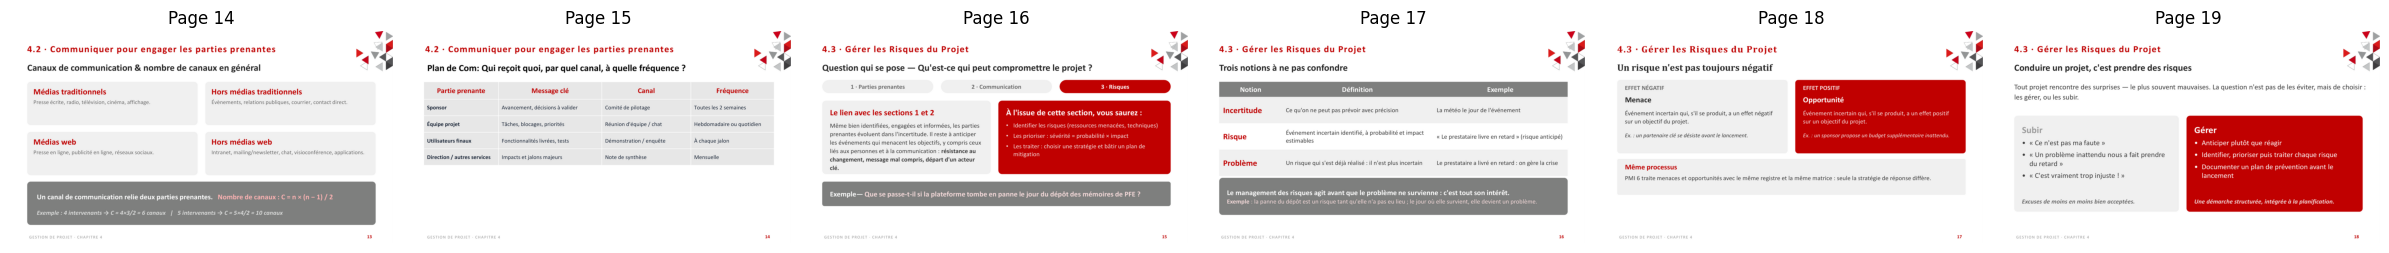

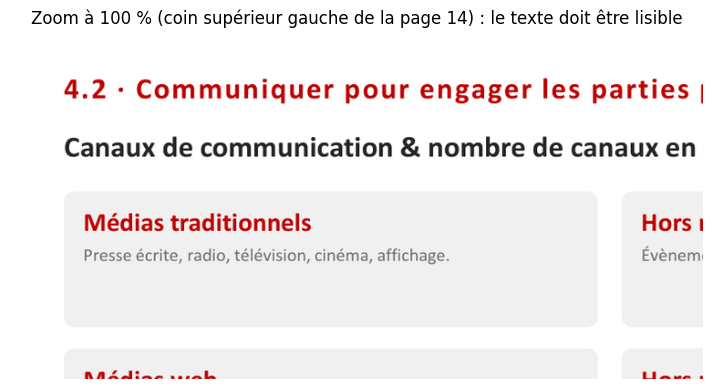

⏱️  Conversion des pages en images : 1.5 s | énergie GPU ≈ 0.02 Wh


{'etape': 'Conversion des pages en images',
 't_debut': 904.141557167,
 't_fin': 905.61027005,
 'duree_s': 1.4687128830000802,
 'temps_cpu_s': 1.4599999999999795,
 'gpu0_pic_pytorch_mo': 8899.68701171875,
 'gpu1_pic_pytorch_mo': 8159.9921875,
 'ram_pic_mo': 1646.21484375,
 'cpu_moyen_pct': 132.125,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 9485.1875,
 'gpu0_puissance_moy_w': 28.74475,
 'gpu0_energie_wh': 0.011727162401004599,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 8743.1875,
 'gpu1_puissance_moy_w': 28.043,
 'gpu1_energie_wh': 0.011440865382769791,
 'energie_gpu_wh': 0.02316802778377439}

In [10]:
PERF.debut("Conversion des pages en images")
TAILLE_TOKEN_PX = 28   # patch 14 px x fusion 2x2
DOSSIER_PAGES = os.path.join(DOSSIER_TRAVAIL, "pages")


def tokens_par_page(n_pages):
    """Répartit le budget de tokens visuels entre les pages."""
    return int(max(TOKENS_MIN_PAR_PAGE, min(TOKENS_MAX_PAR_PAGE, BUDGET_TOKENS_IMAGES // max(1, n_pages))))


def dimensions_multiples_de_28(largeur, hauteur, tokens_max):
    """Plus grandes dimensions multiples de 28 respectant le budget (même logique que `smart_resize` de Qwen)."""
    pixels_max = tokens_max * TAILLE_TOKEN_PX ** 2
    h = max(TAILLE_TOKEN_PX, round(hauteur / TAILLE_TOKEN_PX) * TAILLE_TOKEN_PX)
    w = max(TAILLE_TOKEN_PX, round(largeur / TAILLE_TOKEN_PX) * TAILLE_TOKEN_PX)
    if h * w > pixels_max:
        beta = math.sqrt(hauteur * largeur / pixels_max)
        h = max(TAILLE_TOKEN_PX, math.floor(hauteur / beta / TAILLE_TOKEN_PX) * TAILLE_TOKEN_PX)
        w = max(TAILLE_TOKEN_PX, math.floor(largeur / beta / TAILLE_TOKEN_PX) * TAILLE_TOKEN_PX)
    return w, h


def texte_de_la_page(page, max_caracteres=MAX_CARACTERES_TEXTE_PAGE):
    """Texte de la couche texte du PDF (vide pour un PDF scanné), nettoyé.
    NFC + suppression des caractères de contrôle / privés (puces des polices) : le texte reste identique après
    passage dans le tokenizer, ce que vérifie l'étape 11."""
    try:
        brut = page.get_text("text", sort=True)
    except Exception:
        return ""
    brut = unicodedata.normalize("NFC", brut)
    lignes = []
    for ligne in brut.splitlines():
        ligne = "".join(c if unicodedata.category(c)[0] != "C" else " " for c in ligne)
        ligne = re.sub(r"\s+", " ", ligne).strip()
        if ligne:
            lignes.append(ligne)
    return "\n".join(lignes)[:max_caracteres]


def rendre_pages(doc, tokens_page, dossier):
    """Rend chaque page du PDF en image RGB (ordre conservé), l'enregistre en PNG et extrait son texte."""
    os.makedirs(dossier, exist_ok=True)
    for ancien in os.listdir(dossier):
        if ancien.startswith("page_") and ancien.endswith(".png"):
            os.remove(os.path.join(dossier, ancien))
    pages = []
    for numero in NUMEROS_PAGES:
        page = doc[numero - 1]
        zoom = math.sqrt(tokens_page * TAILLE_TOKEN_PX ** 2 / (page.rect.width * page.rect.height))
        zoom = min(max(zoom, 1.0), 300 / 72)               # entre 72 et 300 DPI
        pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
        image = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        w, h = dimensions_multiples_de_28(image.width, image.height, tokens_page)
        if (w, h) != image.size:
            image = image.resize((w, h), Image.LANCZOS)
        chemin = os.path.join(dossier, f"page_{numero:03d}.png")
        image.save(chemin)
        pages.append({"numero": numero, "image": image, "chemin": chemin, "largeur": w, "hauteur": h,
                      "dpi": 72 * zoom * w / pix.width, "tokens": (w // TAILLE_TOKEN_PX) * (h // TAILLE_TOKEN_PX),
                      "texte": texte_de_la_page(page) if AJOUTER_TEXTE_PDF else ""})
    return pages


TOKENS_PAGE = tokens_par_page(N_PAGES)
PAGES = rendre_pages(DOC_PDF, TOKENS_PAGE, DOSSIER_PAGES)

# --- Vérifications ---
assert len(PAGES) == N_PAGES, "Toutes les pages n'ont pas été converties"
assert [p["numero"] for p in PAGES] == NUMEROS_PAGES, "Ordre des pages non conservé"
assert all(p["largeur"] % 28 == 0 and p["hauteur"] % 28 == 0 for p in PAGES)
TOKENS_IMAGES_TOTAL = sum(p["tokens"] for p in PAGES)
print(f"Budget : {TOKENS_PAGE} tokens maximum par page")
for p in PAGES:
    print(f"   Page {p['numero']} → {os.path.basename(p['chemin'])} : {p['largeur']} × {p['hauteur']} px "
          f"(≈ {p['dpi']:.0f} DPI) → {p['tokens']} tokens visuels"
          + (f" + {len(p['texte'])} caractères de texte" if AJOUTER_TEXTE_PDF else ""))
print(f"✅ {len(PAGES)} images créées dans l'ordre du PDF — {TOKENS_IMAGES_TOTAL} tokens visuels au total")
if AJOUTER_TEXTE_PDF:
    sans_texte = [p["numero"] for p in PAGES if not p["texte"]]
    if sans_texte:
        print(f"ℹ️  Pas de texte extractible pour les pages {sans_texte} (PDF scanné ?) : le modèle lira seulement l'image.")
    print(f"\nTexte extrait de la page {PAGES[0]['numero']} (début) :\n{PAGES[0]['texte'][:400] or '—'}")

# --- Aperçu : miniatures + zoom à 100 % pour contrôler la lisibilité ---
n_apercu = min(len(PAGES), 6)
fig, axes = plt.subplots(1, n_apercu, figsize=(4 * n_apercu, 5.5))
for ax, p in zip(np.atleast_1d(axes), PAGES[:n_apercu]):
    ax.imshow(p["image"]); ax.set_title(f"Page {p['numero']}"); ax.axis("off")
plt.tight_layout(); plt.show()
p0 = PAGES[0]["image"]
plt.figure(figsize=(9, 4.5))
plt.imshow(p0.crop((0, 0, min(p0.width, 760), min(p0.height, 380))))
plt.title(f"Zoom à 100 % (coin supérieur gauche de la page {PAGES[0]['numero']}) : le texte doit être lisible")
plt.axis("off"); plt.show()
PERF.fin()

## 9. Importation et préparation de l'audio

- Formats acceptés : **WAV** et **MP3** (lus par `soundfile` / libsndfile ≥ 1.1 ; repli sur `librosa` si besoin).
- **L'enregistrement original est conservé** : il est copié tel quel (empreinte SHA-256 vérifiée) et n'est jamais modifié.
- **Aucune transcription** : pas de Whisper ni d'autre outil de reconnaissance vocale. Le signal est seulement mis au
  format attendu par Qwen2.5-Omni : **mono, 16 kHz, nombres flottants** (rééchantillonnage de haute qualité `soxr`).
  C'est le modèle qui « écoute » directement ce signal.
- **Volume** (`NORMALISER_VOLUME = True`) : la version envoyée au modèle est ramenée à une crête de 0,9. Un enregistrement
  faible donne un spectrogramme « pâle », plus difficile à comprendre pour l'encodeur audio.
- Contrôles : durée, niveau sonore, saturation, proportion de silence. Au-delà de 300 s, l'audio est découpé en parties
  consécutives, toutes placées **dans le même message** (l'extracteur du modèle tronquerait sinon au-delà de 300 s).

In [11]:
PERF.debut("Préparation de l'audio")
FREQ_QWEN = 16000              # fréquence d'échantillonnage attendue par l'extracteur audio de Qwen2.5-Omni
DUREE_MAX_SEGMENT_S = 300      # n_samples = 4 800 000 échantillons = 300 s par élément audio
EXTENSIONS_AUDIO = (".wav", ".mp3")
EXTENSIONS_AUDIO_TOLEREES = (".flac", ".ogg", ".m4a", ".aac", ".opus", ".webm")   # lues si possible (non garanti)
DOSSIER_AUDIO = os.path.join(DOSSIER_TRAVAIL, "audio")
os.makedirs(DOSSIER_AUDIO, exist_ok=True)


def lire_audio(chemin):
    """Lit un fichier audio en float32 de forme (échantillons, canaux), sans le modifier."""
    try:
        info = sf.info(chemin)
        signal, freq = sf.read(chemin, dtype="float32", always_2d=True)
        return signal, freq, f"soundfile (libsndfile {sf.__libsndfile_version__}), {info.format} / {info.subtype}"
    except Exception as e:
        y, freq = librosa.load(chemin, sr=None, mono=False)   # secours : décodage via audioread / ffmpeg
        signal = np.atleast_2d(y).T.astype(np.float32)
        return signal, int(freq), f"librosa (secours après échec de soundfile : {type(e).__name__})"


def formater_duree(secondes):
    return f"{int(secondes // 60)} min {secondes % 60:04.1f} s"


# --- 9.1 Localisation de l'audio (fourni via CHEMIN_AUDIO, ou cherché dans /kaggle/input) ---
UTILISE_DEMO_AUDIO = False   # conservé pour la traçabilité (toujours False : pas de mode démonstration)
if CHEMIN_AUDIO is None:
    audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO)
    if not audios_trouves:
        audios_trouves = fichiers_presents(DOSSIER_ENTREES, EXTENSIONS_AUDIO_TOLEREES)
        if audios_trouves:
            print(f"⚠️  Aucun WAV/MP3, mais un autre format audio a été trouvé : {audios_trouves[0]} "
                  "(lecture tentée ; en cas d'échec, convertissez-le en WAV ou MP3).")
    if not audios_trouves:
        raise FileNotFoundError(
            f"❌ Aucun fichier WAV/MP3 trouvé dans {DOSSIER_ENTREES}. Renseignez CHEMIN_AUDIO ou ajoutez-le via Add Input → Upload.")
    CHEMIN_AUDIO = audios_trouves[0]
    if len(audios_trouves) > 1:
        print("⚠️  Plusieurs audios trouvés (le premier est utilisé ; sinon renseignez CHEMIN_AUDIO) :")
        for a in audios_trouves:
            print("     -", a)
if not os.path.isfile(CHEMIN_AUDIO):
    raise FileNotFoundError(f"❌ Fichier audio introuvable : {CHEMIN_AUDIO}")
extension = os.path.splitext(CHEMIN_AUDIO)[1].lower()
if extension not in EXTENSIONS_AUDIO:
    print(f"⚠️  Extension {extension} : seuls WAV et MP3 sont garantis ; tentative de lecture quand même.")

# --- 9.2 Conservation de l'original (copie binaire identique, jamais modifiée) ---
CHEMIN_AUDIO_ORIGINAL = os.path.join(DOSSIER_AUDIO, "original" + extension)
shutil.copyfile(CHEMIN_AUDIO, CHEMIN_AUDIO_ORIGINAL)
SHA256_AUDIO = empreinte_sha256(CHEMIN_AUDIO)
assert empreinte_sha256(CHEMIN_AUDIO_ORIGINAL) == SHA256_AUDIO, "La copie de l'original n'est pas identique"

# --- 9.3 Lecture et contrôles de qualité ---
signal, FREQ_ORIGINE, lecteur = lire_audio(CHEMIN_AUDIO)
DUREE_AUDIO_S = signal.shape[0] / FREQ_ORIGINE
if signal.shape[0] == 0 or DUREE_AUDIO_S < 3:
    raise ValueError(f"❌ Audio vide ou trop court ({DUREE_AUDIO_S:.1f} s) : au moins quelques secondes de parole sont nécessaires.")
crete = float(np.max(np.abs(signal)))
rms_db = 20 * np.log10(float(np.sqrt(np.mean(signal ** 2))) + 1e-12)
sature = float(np.mean(np.abs(signal) >= 0.999))
trames = signal.mean(axis=1)[: len(signal) // 400 * 400].reshape(-1, 400)   # trames de ~25 ms à 16 kHz
silence = float(np.mean(20 * np.log10(np.sqrt(np.mean(trames ** 2, axis=1)) + 1e-12) < -45)) if len(trames) else 0.0
print(f"✅ Audio : {CHEMIN_AUDIO}  (lu avec {lecteur})")
print(f"   Durée {formater_duree(DUREE_AUDIO_S)} | {FREQ_ORIGINE} Hz | {signal.shape[1]} canal(aux) | "
      f"crête {crete:.2f} | niveau moyen {rms_db:.1f} dBFS | saturation {100 * sature:.2f} % | silence ≈ {100 * silence:.0f} %")
print(f"   Original conservé à l'identique : {CHEMIN_AUDIO_ORIGINAL} (SHA-256 {SHA256_AUDIO[:16]}…)")
if crete < 0.05:
    print("⚠️  Niveau très faible : rapprochez le micro ou parlez plus fort pour une meilleure compréhension.")
if sature > 0.001:
    print("⚠️  Saturation détectée : baissez le gain du micro lors de l'enregistrement.")
if silence > 0.6:
    print("⚠️  L'enregistrement contient surtout du silence.")
if not 60 <= DUREE_AUDIO_S <= 120:
    print("ℹ️  Pour le premier test, un audio de 1 à 2 minutes est recommandé.")

# --- 9.4 Préparation au format Qwen2.5-Omni : mono, 16 kHz, float32 (aucune transcription) ---
mono = signal.mean(axis=1) if signal.shape[1] > 1 else signal[:, 0]
if FREQ_ORIGINE != FREQ_QWEN:
    audio_16k = librosa.resample(mono, orig_sr=FREQ_ORIGINE, target_sr=FREQ_QWEN, res_type="soxr_hq")
else:
    audio_16k = mono.copy()
# Normalisation du volume (version envoyée au modèle seulement ; l'original reste intact)
GAIN_VOLUME_DB = 0.0
crete_16k = float(np.max(np.abs(audio_16k))) if len(audio_16k) else 0.0
if NORMALISER_VOLUME and crete_16k > 1e-4:
    GAIN_VOLUME_DB = 20 * np.log10(0.9 / crete_16k)
    audio_16k = audio_16k * np.float32(0.9 / crete_16k)
    print(f"🔊 Volume normalisé pour le modèle : gain de {GAIN_VOLUME_DB:+.1f} dB (crête {crete_16k:.2f} → 0.90)")
AUDIO_16K = np.ascontiguousarray(np.nan_to_num(audio_16k), dtype=np.float32)
del signal, mono, audio_16k
assert AUDIO_16K.ndim == 1 and AUDIO_16K.dtype == np.float32
assert abs(len(AUDIO_16K) / FREQ_QWEN - DUREE_AUDIO_S) < 0.01, "La durée a changé lors du rééchantillonnage"

# --- 9.5 Découpage éventuel en parties de 300 s maximum (toutes envoyées dans le même message) ---
n_max = DUREE_MAX_SEGMENT_S * FREQ_QWEN
SEGMENTS_AUDIO = [AUDIO_16K[i:i + n_max] for i in range(0, len(AUDIO_16K), n_max)]
if len(SEGMENTS_AUDIO) > 1 and len(SEGMENTS_AUDIO[-1]) < FREQ_QWEN:   # dernier morceau < 1 s : ignoré (silence de fin)
    SEGMENTS_AUDIO = SEGMENTS_AUDIO[:-1]
CHEMIN_AUDIO_16K = os.path.join(DOSSIER_AUDIO, "audio_16k_mono.wav")
sf.write(CHEMIN_AUDIO_16K, AUDIO_16K, FREQ_QWEN, subtype="FLOAT")
print(f"✅ Audio préparé : mono, {FREQ_QWEN} Hz, {len(AUDIO_16K)} échantillons ({formater_duree(len(AUDIO_16K) / FREQ_QWEN)}) "
      f"→ {len(SEGMENTS_AUDIO)} élément(s) audio ; copie de contrôle : {CHEMIN_AUDIO_16K}")
if len(SEGMENTS_AUDIO) > 1:
    print(f"ℹ️  Audio > {DUREE_MAX_SEGMENT_S} s : découpé en {len(SEGMENTS_AUDIO)} parties consécutives, "
          "toutes envoyées dans le même message.")
print(f"   Tokens audio attendus ≈ {int(len(AUDIO_16K) / FREQ_QWEN * 25)} (25 tokens par seconde)")
PERF.fin()

# --- Écoute ---
if os.path.getsize(CHEMIN_AUDIO) <= 8 * 2**20:
    print("▶️  Enregistrement original :"); display(LecteurAudio(filename=CHEMIN_AUDIO))
print("▶️  Version envoyée au modèle (16 kHz mono" + (", volume normalisé" if NORMALISER_VOLUME else "") + ") — 60 premières secondes :")
display(LecteurAudio(data=AUDIO_16K[: 60 * FREQ_QWEN], rate=FREQ_QWEN))

✅ Audio : /kaggle/input/datasets/eyajall/communication/Voix_261123_202702.mp3  (lu avec soundfile (libsndfile 1.2.2), MP3 / MPEG_LAYER_III)
   Durée 0 min 15.8 s | 48000 Hz | 1 canal(aux) | crête 0.26 | niveau moyen -28.9 dBFS | saturation 0.00 % | silence ≈ 49 %
   Original conservé à l'identique : /kaggle/working/analyse_qwen_omni/audio/original.mp3 (SHA-256 30212b5555f384de…)
ℹ️  Pour le premier test, un audio de 1 à 2 minutes est recommandé.
🔊 Volume normalisé pour le modèle : gain de +10.7 dB (crête 0.26 → 0.90)
✅ Audio préparé : mono, 16000 Hz, 252246 échantillons (0 min 15.8 s) → 1 élément(s) audio ; copie de contrôle : /kaggle/working/analyse_qwen_omni/audio/audio_16k_mono.wav
   Tokens audio attendus ≈ 394 (25 tokens par seconde)
⏱️  Préparation de l'audio : 14.4 s | énergie GPU ≈ 0.23 Wh
▶️  Enregistrement original :


▶️  Version envoyée au modèle (16 kHz mono, volume normalisé) — 60 premières secondes :


## 10. Construction de la requête multimodale unique


In [12]:
PERF.debut("Construction de la requête")
PROMPT_SYSTEME_OFFICIEL = ("You are Qwen, a virtual human developed by the Qwen Team, Alibaba Group, capable of "
                           "perceiving auditory and visual inputs, as well as generating text and speech.")


def construire_consigne(n_pages, n_parties_audio=1):
    parties = "" if n_parties_audio == 1 else f" (en {n_parties_audio} parties consécutives)"
    aide_texte = (" Sous chaque image, le texte de la page extrait du PDF est aussi fourni : sers-t'en pour recopier "
                  "exactement ce que dit le cours." if AJOUTER_TEXTE_PDF else "")
    return f"""Tu es un enseignant expert et rigoureux. Ta tâche : vérifier l'explication orale d'un étudiant en la comparant à son support de cours, puis repérer ses erreurs.

DONNÉES FOURNIES DANS CE MESSAGE :
- Les {n_pages} images ci-dessus sont des pages du cours, dans l'ordre ; le numéro de chaque page (« Page X ») est indiqué juste avant son image.{aide_texte}
- L'enregistrement audio ci-dessus{parties} est l'explication orale de l'étudiant, avec ses propres mots.

TRAVAILLE EN DEUX ÉTAPES ET ÉCRIS LES DEUX ÉTAPES DANS TA RÉPONSE.

ÉTAPE 1 — ÉCOUTE. Écoute l'audio en entier et écris, dans l'ordre, chaque affirmation de l'étudiant (une idée par ligne, numérotée A1, A2, A3…), en reprenant ses mots le plus fidèlement possible. N'ajoute rien qu'il n'a pas dit. Si un passage est inaudible, écris « [inaudible] ».

ÉTAPE 2 — VÉRIFICATION. Pour CHAQUE affirmation de l'étape 1, sans en sauter aucune :
1. trouve la page du cours qui traite de cette notion ;
2. recopie ce que dit le cours sur cette notion ;
3. compare mot à mot l'affirmation et le cours. Ne suppose pas que l'étudiant a raison : vérifie les définitions, les exemples, les chiffres et surtout les inversions entre deux notions (attribuer à une notion ce que le cours dit d'une autre), qui sont les erreurs les plus fréquentes ;
4. donne un verdict :
   - CORRECT : l'affirmation est conforme au cours ;
   - INCORRECT : elle contredit le cours ou elle est fausse (définition incorrecte, notions inversées, exemple mal attribué, chiffre ou formule faux, raisonnement incohérent). Si deux notions sont inversées, chaque affirmation concernée est INCORRECT ;
   - NON VÉRIFIABLE : le cours n'en parle pas, ou le passage est inaudible ;
5. si le verdict est INCORRECT, explique pourquoi et donne la correction selon le cours.
Une notion que l'étudiant n'a pas mentionnée n'est jamais une erreur : ne signale aucun oubli. N'invente aucun contenu.

FORMAT DE LA RÉPONSE (Markdown, en français, exactement cette structure) :

## Étape 1 — Affirmations de l'étudiant
A1 : « … »
A2 : « … »

## Étape 2 — Vérification

### A1
- **Page :** …
- **Le cours dit :** « … »
- **Verdict :** CORRECT, INCORRECT ou NON VÉRIFIABLE
- **Pourquoi :** …
- **Correction :** …

### A2
(même structure, et ainsi de suite pour chaque affirmation ; si le verdict n'est pas INCORRECT, écris « — » pour Pourquoi et Correction)"""


def construire_conversation(pages, segments_audio, consigne):
    """UN SEUL message utilisateur : toutes les pages (+ leur texte) + l'audio + la consigne."""
    duree_totale = sum(len(s) for s in segments_audio) / FREQ_QWEN
    contenu = [{"type": "text", "text": f"Voici le support de cours de l'étudiant ({len(pages)} page(s), dans l'ordre) :\n"}]
    for p in pages:
        contenu.append({"type": "text", "text": f"\n--- Page {p['numero']}/{N_PAGES_PDF} ---\n"})
        contenu.append({"type": "image", "image": p["image"],
                        "resized_width": p["largeur"], "resized_height": p["hauteur"]})   # taille exacte, sans redimensionnement
        if AJOUTER_TEXTE_PDF and p.get("texte"):
            contenu.append({"type": "text", "text": f"\nTexte de la page {p['numero']} (extrait du PDF) :\n{p['texte']}\n"})
    contenu.append({"type": "text", "text": "\n\nVoici l'enregistrement audio original de l'explication orale de "
                                            f"l'étudiant (durée : {formater_duree(duree_totale)}) :\n"})
    for k, segment in enumerate(segments_audio, start=1):
        if len(segments_audio) > 1:
            contenu.append({"type": "text", "text": f"\n[Partie {k}/{len(segments_audio)} de l'enregistrement]\n"})
        contenu.append({"type": "audio", "audio": segment})          # signal brut 16 kHz (np.ndarray float32)
    contenu.append({"type": "text", "text": "\n\n" + consigne})
    return [
        {"role": "system", "content": [{"type": "text", "text": PROMPT_SYSTEME_OFFICIEL}]},
        {"role": "user", "content": contenu},
    ]


def decrire_conversation(conversation):
    """Affiche la structure de la conversation (sans afficher les données brutes)."""
    for message in conversation:
        print(f"[{message['role']}]")
        for element in message["content"]:
            if element["type"] == "image":
                print(f"   🖼️  image {element['image'].size[0]}×{element['image'].size[1]} px")
            elif element["type"] == "audio":
                print(f"   🔊 audio : np.ndarray {element['audio'].dtype}, {len(element['audio'])} échantillons "
                      f"= {len(element['audio']) / FREQ_QWEN:.1f} s à {FREQ_QWEN} Hz")
            else:
                texte = element["text"].strip().replace("\n", " ⏎ ")
                print(f"   📝 texte : {texte[:90]}{'…' if len(texte) > 90 else ''}")


# Début de réponse imposé : le modèle doit écrire tout de suite la 1re affirmation entendue
# (il ne peut plus recopier le modèle de réponse « A1 : « … » » de la consigne).
PREFIXE_REPONSE = "## Étape 1 — Affirmations de l'étudiant\nA1 : «"
CONSIGNE = construire_consigne(N_PAGES, len(SEGMENTS_AUDIO))
CONVERSATION = construire_conversation(PAGES, SEGMENTS_AUDIO, CONSIGNE)
decrire_conversation(CONVERSATION)

# --- Vérifications de structure ---
messages_utilisateur = [m for m in CONVERSATION if m["role"] == "user"]
elements = messages_utilisateur[0]["content"]
n_images = sum(e["type"] == "image" for e in elements)
n_audios = sum(e["type"] == "audio" for e in elements)
assert len(messages_utilisateur) == 1, "Il doit y avoir exactement UN message utilisateur"
assert n_images == N_PAGES, "Toutes les pages doivent être dans le message"
assert n_audios == len(SEGMENTS_AUDIO) >= 1, "L'audio doit être dans le même message"
assert all(isinstance(e["audio"], np.ndarray) for e in elements if e["type"] == "audio"), "L'audio doit être le signal brut"
ordre_pages = [int(re.search(r"Page (\d+)/", e["text"]).group(1)) for e in elements
               if e["type"] == "text" and e["text"].strip().startswith("--- Page")]
assert ordre_pages == NUMEROS_PAGES, "Les pages doivent être dans l'ordre du PDF"
assert "Aucune erreur détectée" not in CONSIGNE, "La consigne ne doit pas proposer de réponse toute faite"
os.makedirs(os.path.join(DOSSIER_TRAVAIL, "resultats"), exist_ok=True)
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "consigne.txt"), "w", encoding="utf-8") as f:
    f.write(CONSIGNE)
n_car_texte_pdf = sum(len(p.get("texte", "")) for p in PAGES) if AJOUTER_TEXTE_PDF else 0
print(f"\n✅ Requête unique prête : 1 message utilisateur = {n_images} image(s) + {n_audios} audio + consigne "
      f"({len(CONSIGNE)} caractères)" + (f" + texte du PDF ({n_car_texte_pdf} caractères)" if n_car_texte_pdf else ""))
PERF.fin()

[system]
   📝 texte : You are Qwen, a virtual human developed by the Qwen Team, Alibaba Group, capable of percei…
[user]
   📝 texte : Voici le support de cours de l'étudiant (7 page(s), dans l'ordre) :
   📝 texte : --- Page 14/31 ---
   🖼️  image 1316×728 px
   📝 texte : Texte de la page 14 (extrait du PDF) : ⏎ 4.2 · Communiquer pour engager les parties prenan…
   📝 texte : --- Page 15/31 ---
   🖼️  image 1316×728 px
   📝 texte : Texte de la page 15 (extrait du PDF) : ⏎ 4.2 · Communiquer pour engager les parties prenan…
   📝 texte : --- Page 16/31 ---
   🖼️  image 1316×728 px
   📝 texte : Texte de la page 16 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Question qui …
   📝 texte : --- Page 17/31 ---
   🖼️  image 1316×728 px
   📝 texte : Texte de la page 17 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Trois notions…
   📝 texte : --- Page 18/31 ---
   🖼️  image 1316×728 px
   📝 texte : Texte de la page 18 (extrait du PDF) : ⏎ 4.3 · Gérer les Risques du Projet ⏎ Un 

{'etape': 'Construction de la requête',
 't_debut': 920.105834392,
 't_fin': 920.118112295,
 'duree_s': 0.012277902999926482,
 'temps_cpu_s': 0.020000000000010232,
 'gpu0_pic_pytorch_mo': 8899.68701171875,
 'gpu1_pic_pytorch_mo': 8159.9921875,
 'ram_pic_mo': 1815.0390625,
 'cpu_moyen_pct': 167.9,
 'gpu0_util_moy_pct': 0.0,
 'gpu0_util_max_pct': 0.0,
 'gpu0_occupe_pic_mo': 9485.1875,
 'gpu0_puissance_moy_w': 28.918,
 'gpu0_energie_wh': 9.862566637552056e-05,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 8743.1875,
 'gpu1_puissance_moy_w': 28.142,
 'gpu1_energie_wh': 9.597909617331418e-05,
 'energie_gpu_wh': 0.00019460476254883475}

## 11. Envoi simultané des images et de l'audio au modèle


In [13]:
PERF.debut("Préparation des entrées (processor)")
LIMITE_CONTEXTE = CONFIG_THINKER.get_text_config().max_position_embeddings


def preparer_entrees(conversation):
    # Gabarit officiel + début de réponse imposé (PREFIXE_REPONSE, section 10)
    texte = processor.apply_chat_template(conversation, add_generation_prompt=True, tokenize=False) + PREFIXE_REPONSE
    audios, images, videos = process_mm_info(conversation, use_audio_in_video=False)
    entrees = processor(text=texte, audio=audios, images=images, videos=videos, return_tensors="pt", padding=True)
    return texte, entrees


def carte_sequence(ids):
    """Résume la séquence en blocs successifs : texte / image / audio."""
    blocs = []
    for t in ids:
        nature = "image" if t == ID_IMAGE else "audio" if t == ID_AUDIO else "texte"
        if blocs and blocs[-1][0] == nature:
            blocs[-1][1] += 1
        else:
            blocs.append([nature, 1])
    return blocs


TEXTE_GABARIT, ENTREES = preparer_entrees(CONVERSATION)
# Sécurité : si la séquence est trop longue pour le contexte, on réduit la résolution des pages
while ENTREES["input_ids"].shape[1] + MAX_NOUVEAUX_TOKENS > LIMITE_CONTEXTE and TOKENS_PAGE > 128:
    TOKENS_PAGE = int(TOKENS_PAGE * 0.75)
    print(f"⚠️  Séquence trop longue : pages réduites à {TOKENS_PAGE} tokens maximum chacune.")
    PAGES = rendre_pages(DOC_PDF, TOKENS_PAGE, DOSSIER_PAGES)
    CONVERSATION = construire_conversation(PAGES, SEGMENTS_AUDIO, CONSIGNE)
    TEXTE_GABARIT, ENTREES = preparer_entrees(CONVERSATION)

ids = ENTREES["input_ids"][0].tolist()
N_TOKENS_ENTREE = len(ids)
N_TOKENS_IMAGE = ids.count(ID_IMAGE)
N_TOKENS_AUDIO = ids.count(ID_AUDIO)
TOKENS_IMAGE_ATTENDUS = int((ENTREES["image_grid_thw"].prod(-1) // 4).sum())
DUREE_VUE_PAR_PROCESSOR_S = float(ENTREES["feature_attention_mask"].sum()) / 100   # 100 trames Mel par seconde

print("Tenseurs transmis au modèle :")
for nom, valeur in ENTREES.items():
    print(f"   {nom:24s} {tuple(valeur.shape)} {str(valeur.dtype).replace('torch.', '')}")
print(f"\nSéquence unique de {N_TOKENS_ENTREE} tokens : {N_TOKENS_IMAGE} tokens image + {N_TOKENS_AUDIO} tokens audio "
      f"+ {N_TOKENS_ENTREE - N_TOKENS_IMAGE - N_TOKENS_AUDIO} tokens de texte")
print("Ordre dans la séquence : " + " → ".join(f"{nature}({n})" for nature, n in carte_sequence(ids)))

# --- Vérifications ---
assert ENTREES["input_ids"].shape[0] == 1, "Une seule séquence (une seule requête)"
assert ENTREES["image_grid_thw"].shape[0] == N_PAGES, "Chaque page doit être une image distincte"
assert N_TOKENS_IMAGE == TOKENS_IMAGE_ATTENDUS == sum(p["tokens"] for p in PAGES), "Tokens image incohérents"
assert N_TOKENS_AUDIO > 0 and "input_features" in ENTREES, "L'audio doit être dans la même séquence"
assert abs(DUREE_VUE_PAR_PROCESSOR_S - len(AUDIO_16K) / FREQ_QWEN) < 0.05, "L'audio a été tronqué !"
# Le seul texte de la séquence est notre gabarit (étiquettes + consigne) : aucune transcription n'y a été insérée
def texte_sequence_conforme(entrees, gabarit):
    """Vrai si, en retirant les tokens image/audio, la séquence est exactement notre gabarit (consigne + étiquettes)."""
    ids_texte = [t for t in entrees["input_ids"][0].tolist() if t not in (ID_IMAGE, ID_AUDIO)]
    texte = processor.tokenizer.decode(ids_texte, skip_special_tokens=False, clean_up_tokenization_spaces=False)
    return texte == gabarit.replace("<|IMAGE|>", "").replace("<|AUDIO|>", "")


TEXTE_SEQUENCE_CONFORME = texte_sequence_conforme(ENTREES, TEXTE_GABARIT)
assert TEXTE_SEQUENCE_CONFORME, "La séquence contient du texte inattendu"
print(f"✅ Pages : {ENTREES['image_grid_thw'].shape[0]} images, {N_TOKENS_IMAGE} tokens | "
      f"Audio : {DUREE_VUE_PAR_PROCESSOR_S:.2f} s transmises sur {len(AUDIO_16K) / FREQ_QWEN:.2f} s (non tronqué), "
      f"{N_TOKENS_AUDIO} tokens | texte = gabarit uniquement")
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "gabarit_requete.txt"), "w", encoding="utf-8") as f:
    f.write(TEXTE_GABARIT)

# --- Estimation de la mémoire de calcul pour cette séquence ---
cfg_texte = CONFIG_THINKER.get_text_config()
tete = cfg_texte.hidden_size // cfg_texte.num_attention_heads
cache_kv_gio = (cfg_texte.num_hidden_layers * 2 * (N_TOKENS_ENTREE + MAX_NOUVEAUX_TOKENS)
                * cfg_texte.num_key_value_heads * tete * 2) / 2**30
transitoire_gio = N_TOKENS_ENTREE * cfg_texte.intermediate_size * 2 * 3 / 2**30
if torch.cuda.is_available():
    mesurer_memoire_libre(GPU_UTILISABLES)
libre_min = min(g["libre_gio"] for g in GPU_UTILISABLES)
print(f"Mémoire de calcul estimée : cache KV ≈ {cache_kv_gio:.2f} Gio (réparti), pic transitoire ≈ {transitoire_gio:.2f} Gio "
      f"par GPU ; mémoire libre minimale sur un GPU : {libre_min:.2f} Gio")
if transitoire_gio + cache_kv_gio > libre_min:
    print("⚠️  Marge mémoire faible : en cas d'erreur mémoire, la résolution des pages sera réduite automatiquement.")

# --- Transfert vers le GPU de la couche d'entrée (accelerate déplace ensuite les tenseurs entre GPU) ---
PERIPHERIQUE_ENTREE = model.get_input_embeddings().weight.device
ENTREES_MODELE = ENTREES.to(PERIPHERIQUE_ENTREE).to(DTYPE)   # seuls les tenseurs flottants passent en 16 bits
print(f"✅ Entrées placées sur {PERIPHERIQUE_ENTREE} : pixel_values {ENTREES_MODELE['pixel_values'].dtype}, "
      f"input_features {ENTREES_MODELE['input_features'].dtype}")
PERF.fin()

Tenseurs transmis au modèle :
   input_ids                (1, 11351) int64
   attention_mask           (1, 11351) int64
   pixel_values             (34216, 1176) float32
   image_grid_thw           (7, 3) int64
   input_features           (1, 128, 30000) float32
   feature_attention_mask   (1, 30000) int32

Séquence unique de 11351 tokens : 8554 tokens image + 394 tokens audio + 2403 tokens de texte
Ordre dans la séquence : texte(75) → image(1222) → texte(231) → image(1222) → texte(187) → image(1222) → texte(268) → image(1222) → texte(227) → image(1222) → texte(206) → image(1222) → texte(206) → image(1222) → texte(247) → audio(394) → texte(756)
✅ Pages : 7 images, 8554 tokens | Audio : 15.77 s transmises sur 15.77 s (non tronqué), 394 tokens | texte = gabarit uniquement
Mémoire de calcul estimée : cache KV ≈ 0.72 Gio (réparti), pic transitoire ≈ 1.20 Gio par GPU ; mémoire libre minimale sur un GPU : 5.74 Gio
✅ Entrées placées sur cuda:0 : pixel_values torch.float16, input_features torc

{'etape': 'Préparation des entrées (processor)',
 't_debut': 920.145777651,
 't_fin': 920.800095286,
 'duree_s': 0.654317634999984,
 'temps_cpu_s': 0.9800000000000182,
 'gpu0_pic_pytorch_mo': 9152.19287109375,
 'gpu1_pic_pytorch_mo': 8159.9921875,
 'ram_pic_mo': 2147.4609375,
 'cpu_moyen_pct': 129.5,
 'gpu0_util_moy_pct': 2.3333333333333335,
 'gpu0_util_max_pct': 7.0,
 'gpu0_occupe_pic_mo': 9745.1875,
 'gpu0_puissance_moy_w': 28.917999999999996,
 'gpu0_energie_wh': 0.0052559881580359815,
 'gpu1_util_moy_pct': 0.0,
 'gpu1_util_max_pct': 0.0,
 'gpu1_occupe_pic_mo': 8743.1875,
 'gpu1_puissance_moy_w': 28.241,
 'gpu1_energie_wh': 0.005132940091676263,
 'energie_gpu_wh': 0.010388928249712244}

## 12. Génération de l'analyse (mesurée)

Un seul appel à `generate`. Le modèle écrit d'abord ce qu'il a entendu (étape 1), puis vérifie chaque affirmation
(étape 2) ; l'affichage en direct montre tout de suite s'il a bien compris l'audio. **Si l'étape 1 ne correspond pas à ce
qui a été dit, le problème vient de l'audio** (volume, débit, bruit, micro), pas de la comparaison avec le cours.

L'appel est mesuré : temps de lecture de l'entrée (jusqu'au 1er token), vitesse d'écriture, tokens, pic de mémoire sur
chaque GPU, énergie.

In [14]:
PERF.debut("Analyse conjointe (écoute + vérification)")


class DetecteurInstabilite(LogitsProcessor):
    """Interrompt la génération dès que des valeurs NaN/inf apparaissent (débordement numérique en FP16)."""
    def __call__(self, input_ids, scores):
        if not torch.isfinite(scores).all():
            raise FloatingPointError("valeurs NaN/inf dans les logits")
        return scores


class TraceurModalites:
    """Enregistre ce que reçoivent réellement les encodeurs vision et audio pendant la génération."""
    def __init__(self, modele):
        self.modele, self.appels, self.crochets = modele, {"vision": [], "audio": []}, []

    def __enter__(self):
        def crochet_vision(module, args, kwargs, sortie):
            pixels = args[0] if args else kwargs["hidden_states"]
            grille = kwargs.get("grid_thw", args[1] if len(args) > 1 else None)
            self.appels["vision"].append({"images": int(grille.shape[0]), "patchs": int(pixels.shape[0]),
                                          "grilles": grille.tolist()})

        def crochet_audio(module, args, kwargs, sortie):
            mel = args[0] if args else kwargs["input_features"]
            self.appels["audio"].append({"canaux_mel": int(mel.shape[0]), "trames": int(mel.shape[-1]),
                                         "secondes": int(mel.shape[-1]) / 100})

        self.crochets = [
            self.modele.model.visual.register_forward_hook(crochet_vision, with_kwargs=True),
            self.modele.model.audio_tower.register_forward_hook(crochet_audio, with_kwargs=True),
        ]
        return self

    def __exit__(self, *exc):
        for c in self.crochets:
            c.remove()


class StreamerChrono(TextStreamer):
    """Affiche la réponse en direct ET note l'instant où le premier token est écrit (fin de la lecture de l'entrée)."""
    def __init__(self, tokenizer, afficher=True):
        super().__init__(tokenizer, skip_prompt=True, skip_special_tokens=True)
        self.afficher, self.t_premier_token = afficher, None

    def put(self, value):
        if not self.next_tokens_are_prompt and self.t_premier_token is None:
            self.t_premier_token = time.perf_counter()
        super().put(value)

    def on_finalized_text(self, text, stream_end=False):
        if self.afficher:
            super().on_finalized_text(text, stream_end)


def resume_inference(m):
    return (f"   ⏱️  {m['duree_s']:.1f} s (lecture de l'entrée {m['ttft_s']:.1f} s + écriture "
            f"{m['tokens_sortie']} tokens à {m['vitesse_ecriture_tok_s']:.1f} tokens/s) | entrée {m['tokens_entree']} tokens "
            f"(image {m['tokens_image']}, audio {m['tokens_audio']}, texte {m['tokens_texte']}) | "
            f"mémoire PyTorch pic : " + " / ".join(f"GPU{i} {m.get(f'gpu{i}_pic_pytorch_mo', 0) / 1024:.1f} Gio"
                                                  for i in range(PERF.n_gpu))
            + f" | énergie ≈ {m['energie_gpu_wh']:.2f} Wh")


NB_APPELS_GENERATE = 0


def generer_rapport(entrees, max_nouveaux_tokens=MAX_NOUVEAUX_TOKENS, en_direct=AFFICHER_EN_DIRECT):
    """UNE requête : pages + audio + consigne → texte du rapport, mesurée (temps, tokens, mémoire, énergie)."""
    global NB_APPELS_GENERATE
    streamer = StreamerChrono(processor.tokenizer, afficher=en_direct)   # note aussi l'heure du 1er token
    parametres = dict(
        max_new_tokens=max_nouveaux_tokens,
        do_sample=ECHANTILLONNAGE,
        repetition_penalty=1.05,
        eos_token_id=[ID_IM_END, ID_ENDOFTEXT],   # arrêt explicite sur <|im_end|>
        pad_token_id=ID_ENDOFTEXT,
        logits_processor=LogitsProcessorList([DetecteurInstabilite()]),
        streamer=streamer,
    )
    if ECHANTILLONNAGE:
        parametres.update(temperature=0.7, top_p=0.8, top_k=20)
    ids = entrees["input_ids"][0].tolist()
    n_image, n_audio = ids.count(ID_IMAGE), ids.count(ID_AUDIO)
    NB_APPELS_GENERATE += 1
    if en_direct:
        print(PREFIXE_REPONSE, end="", flush=True)            # début de réponse imposé (section 10)
    mesure = PERF.debut_inference("Analyse conjointe (pages + audio)", adaptateur="—",
                                  precision=f"{str(DTYPE).replace('torch.', '')} ({STRATEGIE['mode']})",
                                  tokens_entree=len(ids), tokens_image=n_image, tokens_audio=n_audio,
                                  tokens_texte=len(ids) - n_image - n_audio)
    with torch.inference_mode(), TraceurModalites(model) as traceur:
        sortie = model.generate(**entrees, **parametres)
    nouveaux = sortie[:, entrees["input_ids"].shape[1]:]
    PERF.fin_inference(mesure, streamer.t_premier_token, int(nouveaux.shape[1]))
    mesure["limite_atteinte"] = int(nouveaux.shape[1]) >= max_nouveaux_tokens
    texte = processor.batch_decode(nouveaux, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    return (PREFIXE_REPONSE + texte).strip(), int(nouveaux.shape[1]), traceur.appels, mesure


def encodeurs_en_fp32():
    """Passe les encodeurs vision et audio en FP32 (secours en cas d'instabilité FP16)."""
    besoin_gio = (N_PARAMS_PAR_BLOC["encodeur audio"] + N_PARAMS_PAR_BLOC["encodeur vision"]) * 2 / 2**30
    if torch.cuda.is_available():
        appareil = next(model.model.visual.parameters()).device
        if appareil.type == "cuda" and torch.cuda.mem_get_info(appareil)[0] / 2**30 < besoin_gio + 1:
            return False
    model.model.visual.float()
    model.model.audio_tower.float()
    return True


facteurs_resolution = iter([0.7, 0.5])
ENCODEURS_FP32, TENTATIVES = False, []
t_debut = time.time()
while True:
    try:
        print(f"⏳ Analyse conjointe en cours ({N_TOKENS_ENTREE} tokens d'entrée : {N_PAGES} page(s) + "
              f"{formater_duree(len(AUDIO_16K) / FREQ_QWEN)} d'audio)…\n" + "─" * 72)
        t0 = time.time()
        RAPPORT_BRUT, N_TOKENS_GENERES, TRACE_MODALITES, MESURE_ANALYSE = generer_rapport(ENTREES_MODELE)
        DUREE_GENERATION_S = time.time() - t0
        print("\n" + "─" * 72)
        break
    except Exception as e:
        TENTATIVES.append(f"{type(e).__name__}: {str(e)[:200]}")
        liberer_memoire()
        if est_erreur_memoire(e):
            facteur = next(facteurs_resolution, None)
            if facteur is None:
                raise RuntimeError("❌ Mémoire GPU insuffisante même avec des pages moins résolues. Utilisez 'GPU T4 x2', "
                                   "réduisez BUDGET_TOKENS_IMAGES ou raccourcissez l'audio.") from e
            TOKENS_PAGE = int(TOKENS_PAGE * facteur)
            if TOKENS_PAGE < 128:
                raise RuntimeError("❌ Mémoire GPU insuffisante : les pages sont déjà au minimum de résolution. Réduisez le "
                                   "nombre de pages (PAGES_A_ANALYSER) ou la durée de l'audio.") from e
            print(f"\n⚠️  Mémoire GPU insuffisante → nouvelle requête unique avec des pages à {TOKENS_PAGE} tokens maximum.")
            PAGES = rendre_pages(DOC_PDF, TOKENS_PAGE, DOSSIER_PAGES)
            CONVERSATION = construire_conversation(PAGES, SEGMENTS_AUDIO, CONSIGNE)
            TEXTE_GABARIT, ENTREES = preparer_entrees(CONVERSATION)
            N_TOKENS_ENTREE = ENTREES["input_ids"].shape[1]
            N_TOKENS_IMAGE = int((ENTREES["input_ids"] == ID_IMAGE).sum())
            N_TOKENS_AUDIO = int((ENTREES["input_ids"] == ID_AUDIO).sum())
            ENTREES_MODELE = ENTREES.to(PERIPHERIQUE_ENTREE).to(DTYPE)
            continue
        if isinstance(e, FloatingPointError) and DTYPE == torch.float16 and not ENCODEURS_FP32:
            ENCODEURS_FP32 = encodeurs_en_fp32()
            if ENCODEURS_FP32:
                print("\n⚠️  Instabilité numérique FP16 détectée → encodeurs vision et audio passés en FP32, nouvelle tentative.")
                continue
        if isinstance(e, FloatingPointError):
            raise RuntimeError("❌ Instabilité numérique persistante en FP16 (NaN/inf) malgré les encodeurs en FP32. "
                               "Utilisez si possible un GPU compatible BF16 (architecture Ampere ou plus récente), "
                               "ou réduisez BUDGET_TOKENS_IMAGES et la durée de l'audio.") from e
        if any(m in str(e) for m in ("CUDA error", "CUBLAS", "cuDNN", "illegal memory access", "device-side assert")):
            raise RuntimeError("❌ Erreur CUDA grave : le GPU est dans un état instable. Faites Run → Restart & clear cell "
                               "outputs, puis relancez le notebook.") from e
        raise

DUREE_TOTALE_S = time.time() - t_debut
print(f"✅ Rapport généré en {DUREE_GENERATION_S:.0f} s : {N_TOKENS_GENERES} tokens "
      f"({N_TOKENS_GENERES / max(DUREE_GENERATION_S, 1e-6):.1f} tokens/s)"
      + (f" — après {len(TENTATIVES)} tentative(s) de secours" if TENTATIVES else ""))
print(resume_inference(MESURE_ANALYSE))

# --- Ce que les encodeurs ont réellement reçu pendant CET appel ---
for appel in TRACE_MODALITES["vision"]:
    print(f"   👁️  Encodeur vision : {appel['images']} image(s), {appel['patchs']} patchs, grilles (t, h, w) = {appel['grilles']}")
for appel in TRACE_MODALITES["audio"]:
    print(f"   👂 Encodeur audio  : spectrogramme {appel['canaux_mel']} canaux Mel × {appel['trames']} trames "
          f"= {appel['secondes']:.2f} s de signal")

# --- Contrôle de la sortie ---
ALERTES_SORTIE = []
if len(RAPPORT_BRUT) < 300:
    ALERTES_SORTIE.append("rapport très court")
if re.search(r"(.)\1{30,}", RAPPORT_BRUT):
    ALERTES_SORTIE.append("répétition anormale de caractères (signe d'instabilité numérique)")
if N_TOKENS_GENERES >= MAX_NOUVEAUX_TOKENS:
    ALERTES_SORTIE.append("limite de longueur atteinte : rapport peut-être tronqué (augmentez MAX_NOUVEAUX_TOKENS)")
for a in ALERTES_SORTIE:
    print("⚠️ ", a)
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "reponse_brute_modele.md"), "w", encoding="utf-8") as f:
    f.write(RAPPORT_BRUT)
PERF.fin()

⏳ Analyse conjointe en cours (11351 tokens d'entrée : 7 page(s) + 0 min 15.8 s d'audio)…
────────────────────────────────────────────────────────────────────────
## Étape 1 — Affirmations de l'étudiant
A1 : « Incertitude, c'est événement incertain identifié à probabilité et impact estimables. »
A2 : « Le risque, c'est ce qu'on peut pas prévoir avec précision. »

## Étape 2 — Vérification

### A1
- **Page :** Page 17
- **Le cours dit :** « Incertitude : Ce qu'on ne peut pas prévoir avec précision. »
- **Verdict :** INCORRECT
- **Pourquoi :** L'étudiant a inversé les définitions. Le cours dit que l'incertitude est ce qu'on ne peut pas prévoir avec précision, tandis que l'étudiant dit que le risque est ce qu'on ne peut pas prévoir avec précision.
- **Correction :** Incertitude : Ce qu'on ne peut pas prévoir avec précision. Le risque : Événement incertain identifié, à probabilité et impact estimables.

### A2
- **Page :** Page 17
- **Le cours dit :** « Risque : Événement incertain identifi

{'etape': 'Analyse conjointe (écoute + vérification)',
 't_debut': 920.840532352,
 't_fin': 972.41373533,
 'duree_s': 51.57320297800004,
 'temps_cpu_s': 49.589999999999975,
 'gpu0_pic_pytorch_mo': 11001.08740234375,
 'gpu1_pic_pytorch_mo': 9984.5556640625,
 'ram_pic_mo': 2680.4296875,
 'cpu_moyen_pct': 96.34615384615384,
 'gpu0_util_moy_pct': 40.01923076923077,
 'gpu0_util_max_pct': 100.0,
 'gpu0_occupe_pic_mo': 11855.1875,
 'gpu0_puissance_moy_w': 51.16563461538462,
 'gpu0_energie_wh': 0.7329932387548378,
 'gpu1_util_moy_pct': 45.24038461538461,
 'gpu1_util_max_pct': 100.0,
 'gpu1_occupe_pic_mo': 10683.1875,
 'gpu1_puissance_moy_w': 56.41388461538462,
 'gpu1_energie_wh': 0.8081790894574179,
 'energie_gpu_wh': 1.5411723282122556}

## 13. Extraction des erreurs et des corrections

La réponse du modèle est découpée en affirmations (A1, A2…) avec leur page, ce que dit le cours, le verdict,
l'explication et la correction. Le verdict retenu est le **premier** écrit par le modèle (« INCORRECT — ce n'est pas
conforme au cours » reste INCORRECT) ; une affirmation vide ou une liste de verdicts recopiée est classée `INCONNU`.
**« Aucune erreur » n'est conclu que si toutes les affirmations ont un verdict CORRECT, INCORRECT ou NON VÉRIFIABLE** ;
sinon le rapport indique « analyse incomplète ».

In [15]:
PERF.debut("Extraction des erreurs")
VERDICTS_VALIDES = ("CORRECT", "INCORRECT", "NON VÉRIFIABLE")


def sans_accents(texte):
    return "".join(c for c in unicodedata.normalize("NFKD", texte or "") if not unicodedata.combining(c))


def nettoyer(valeur):
    """Retire le gras Markdown, les guillemets et les valeurs vides (« — », « … ») autour d'une valeur."""
    v = (valeur or "").strip().strip("*").strip()
    v = v.strip("«»\"“”").strip()
    return "" if v.lower() in ("", "-", "—", "–", "…", "...", "n/a", "aucun", "aucune", "néant") else v


def nettoyer_reponse(texte):
    texte = re.sub(r"^```(?:markdown|md)?\s*\n", "", (texte or "").strip())
    return re.sub(r"\n```\s*$", "", texte).replace("\r\n", "\n").strip()


RE_ETAPE_2 = re.compile(r"^[ \t]*(?:#{1,4}|\*\*)[^\n]*(?:[ÉEé]tape[ \t]*2|v[ée]rification)", re.I | re.M)
RE_AFFIRMATION = re.compile(r"^[ \t]*(?:[-*•][ \t]*)?\**[ \t]*A[ \t]?(\d+)[ \t]*\**[ \t]*[:：.)\-–—][ \t]*\**[ \t]*(.+?)[ \t]*$", re.M)
RE_BLOC = re.compile(r"^[ \t]*#{2,5}[ \t]*\**[ \t]*A[ \t]?(\d+)\b[ \t]*\**[ \t]*[:：.\-–—]?[ \t]*(.*?)[ \t]*$", re.M)
RE_CHAMP = re.compile(r"^\s*(?:[-*•]\s*)?\**\s*([^:：*\n]{2,40}?)\s*\**\s*[:：]\s*\**\s*(.*?)\s*$")


def type_de_champ(etiquette):
    e = sans_accents(etiquette).lower().strip()
    if e.startswith("page"):
        return "page"
    if "verdict" in e:
        return "verdict"
    if e.startswith("correction"):
        return "correction"
    if "cours" in e:
        return "cours"
    if e.startswith(("pourquoi", "explication", "raison", "justification")):
        return "pourquoi"
    if e.startswith(("affirmation", "ce que", "etudiant", "l'etudiant")):
        return "affirmation"
    return None


def classer_verdict(verdict):
    """CORRECT / INCORRECT / NON VÉRIFIABLE d'après le PREMIER verdict écrit par le modèle ;
    INCONNU si aucun verdict, ou si le modèle a recopié la liste « CORRECT, INCORRECT ou NON VÉRIFIABLE »."""
    t = sans_accents(verdict or "").upper()
    if re.search(r"\bCORRECTE?\W+(?:OU\W+)?INCORRECTE?\b", t):
        return "INCONNU"
    motifs = [
        ("INCORRECT", r"\bINCORRECTE?\b|\bFAUSSE?\b|\bFAUX\b|\bERRONEE?\b|\bINEXACTE?\b|PARTIELLEMENT"
                      r"|\b(?:NON|PAS)[ \-](?:CONFORME|CORRECTE?|EXACTE?|JUSTE)\b"),
        ("NON VÉRIFIABLE", r"NON[ \-]VERIFIABLE|\bINVERIFIABLE\b|\bINAUDIBLE\b|PAS DANS LE COURS|HORS (?:DU )?COURS"),
        ("CORRECT", r"\bCORRECTE?\b|\bJUSTE\b|\bCONFORME\b|\bEXACTE?\b"),
    ]
    positions = []
    for nom, motif in motifs:
        m = re.search(motif, t)
        if m:
            positions.append((m.start(), nom))
    return min(positions)[1] if positions else "INCONNU"


def analyser_reponse(texte):
    """Découpe la réponse du modèle (étape 1 : affirmations, étape 2 : vérification) en une liste d'affirmations
    avec leur verdict. Tolère les petites variations de format (gras, guillemets, titres)."""
    texte = nettoyer_reponse(texte)
    m_etape2, m_bloc = RE_ETAPE_2.search(texte), RE_BLOC.search(texte)
    debut_etape2 = min([m.start() for m in (m_etape2, m_bloc) if m], default=len(texte))
    partie1, partie2 = texte[:debut_etape2], texte[debut_etape2:]

    affirmations = {}
    for m in RE_AFFIRMATION.finditer(partie1):
        affirmations.setdefault(int(m.group(1)), nettoyer(m.group(2)))
    if not affirmations:   # numérotation « 1. … » au lieu de « A1 : … »
        for m in re.finditer(r"^[ \t]*(\d+)[ \t]*[.)][ \t]+(.+?)[ \t]*$", partie1, re.M):
            affirmations.setdefault(int(m.group(1)), nettoyer(m.group(2)))

    blocs = {}
    entetes = list(RE_BLOC.finditer(partie2))
    for k, m in enumerate(entetes):
        fin = entetes[k + 1].start() if k + 1 < len(entetes) else len(partie2)
        champs, dernier = {"titre": m.group(2)}, None
        for ligne in partie2[m.end():fin].splitlines():
            if not ligne.strip() or ligne.lstrip().startswith("#"):
                continue
            mc = RE_CHAMP.match(ligne)
            cle = type_de_champ(mc.group(1)) if mc else None
            if cle:
                champs[cle], dernier = mc.group(2), cle
            elif dernier:
                champs[dernier] += " " + ligne.strip().lstrip("-*• ").strip()
        blocs.setdefault(int(m.group(1)), champs)

    analyse = []
    for n in sorted(set(affirmations) | set(blocs)):
        c = blocs.get(n, {})
        analyse.append({
            "id": f"A{n}",
            "affirmation": affirmations.get(n) or nettoyer(c.get("affirmation")) or nettoyer(c.get("titre")),
            "page": re.sub(r"(?i)^pages?\s*", "", nettoyer(c.get("page"))),
            "cours": nettoyer(c.get("cours")),
            "verdict": classer_verdict(c.get("verdict")) if n in blocs else "NON TRAITÉE",
            "pourquoi": nettoyer(c.get("pourquoi")),
            "correction": nettoyer(c.get("correction")),
        })
    return analyse


def recopie_de_consigne(a):
    """Le modèle a-t-il recopié le modèle de réponse de la consigne au lieu de répondre ?"""
    texte = sans_accents(" ".join(str(a.get(k) or "") for k in ("page", "cours", "pourquoi", "correction"))).lower()
    return any(m in texte for m in ("recopie la phrase", "numero de la page", "un seul des trois", "correct, incorrect ou"))


ANALYSE = analyser_reponse(RAPPORT_BRUT)
for a in ANALYSE:
    a["probleme"] = ""
    if not a["affirmation"]:
        a["verdict"], a["probleme"] = "INCONNU", "affirmation vide : le modèle a recopié le modèle de réponse"
    elif recopie_de_consigne(a):
        a["verdict"], a["probleme"] = "INCONNU", "le modèle a recopié la consigne au lieu de répondre"
    elif a["verdict"] == "NON TRAITÉE":
        a["probleme"] = "entendue mais pas vérifiée (réponse tronquée ?)"
    elif a["verdict"] == "INCONNU":
        a["probleme"] = "verdict absent ou ambigu"
ERREURS = [a for a in ANALYSE if a["verdict"] == "INCORRECT"]
COMPTE_VERDICTS = Counter(a["verdict"] for a in ANALYSE)
SANS_VERDICT = [a for a in ANALYSE if a["verdict"] not in VERDICTS_VALIDES]
# « Aucune erreur » n'est conclu que si TOUTES les affirmations ont reçu un vrai verdict
ANALYSE_COMPLETE = bool(ANALYSE) and not SANS_VERDICT

ALERTES_ANALYSE = []
if not ANALYSE:
    ALERTES_ANALYSE.append("le modèle n'a restitué aucune affirmation de l'étudiant (format non respecté ou audio non "
                           "compris) : lisez sa réponse brute ci-dessous")
if SANS_VERDICT:
    ALERTES_ANALYSE.append(f"{len(SANS_VERDICT)} affirmation(s) sans verdict exploitable : "
                           + ", ".join(f"{a['id']} ({a['probleme']})" for a in SANS_VERDICT)
                           + (" — augmentez MAX_NOUVEAUX_TOKENS" if any(a["verdict"] == "NON TRAITÉE" for a in SANS_VERDICT) else ""))
if ANALYSE and all(a["verdict"] == "NON VÉRIFIABLE" for a in ANALYSE):
    ALERTES_ANALYSE.append("aucune affirmation n'a pu être rattachée au cours : explication hors sujet, mauvaises pages "
                           "(PAGES_A_ANALYSER) ou audio mal compris")
if any("inaudible" in a["affirmation"].lower() for a in ANALYSE):
    ALERTES_ANALYSE.append("passage(s) jugé(s) inaudible(s) par le modèle : réenregistrez plus près du micro")

print(f"Affirmations entendues : {len(ANALYSE)} | " +
      " | ".join(f"{v} : {n}" for v, n in COMPTE_VERDICTS.most_common()))
for a in ANALYSE:
    print(f"   {a['id']:4s} [{a['verdict']:14s}] p.{a['page'] or '?':>3s}  « {a['affirmation'][:100]} »"
          + (f"  ⚠️ {a['probleme']}" if a["probleme"] else ""))
for alerte in ALERTES_ANALYSE:
    print("⚠️ ", alerte)
if ERREURS:
    print(f"\n❌ {len(ERREURS)} erreur(s) détectée(s)")
elif ANALYSE_COMPLETE:
    print(f"\n✅ Aucune erreur détectée : les {len(ANALYSE)} affirmation(s) ont toutes reçu un verdict")
else:
    print("\n⚠️  Analyse incomplète : impossible de conclure qu'il n'y a pas d'erreur (voir les alertes)")
with open(os.path.join(DOSSIER_TRAVAIL, "resultats", "analyse.json"), "w", encoding="utf-8") as f:
    json.dump(ANALYSE, f, ensure_ascii=False, indent=2)
PERF.fin(afficher=False)

Affirmations entendues : 2 | INCORRECT : 2
   A1   [INCORRECT     ] p. 17  « Incertitude, c'est événement incertain identifié à probabilité et impact estimables. »
   A2   [INCORRECT     ] p. 17  « Le risque, c'est ce qu'on peut pas prévoir avec précision. »

❌ 2 erreur(s) détectée(s)


{'etape': 'Extraction des erreurs',
 't_debut': 972.464100621,
 't_fin': 972.483701389,
 'duree_s': 0.019600768000032076,
 'temps_cpu_s': 0.009999999999990905,
 'gpu0_pic_pytorch_mo': 8985.048828125,
 'gpu1_pic_pytorch_mo': 8160.9921875,
 'ram_pic_mo': 2681.00390625,
 'cpu_moyen_pct': 108.6,
 'gpu0_util_moy_pct': 33.0,
 'gpu0_util_max_pct': 33.0,
 'gpu0_occupe_pic_mo': 11855.1875,
 'gpu0_puissance_moy_w': 42.044,
 'gpu0_energie_wh': 0.00022891519160926348,
 'gpu1_util_moy_pct': 48.0,
 'gpu1_util_max_pct': 48.0,
 'gpu1_occupe_pic_mo': 10683.1875,
 'gpu1_puissance_moy_w': 80.764,
 'gpu1_energie_wh': 0.000439732340765164,
 'energie_gpu_wh': 0.0006686475323744275}

## 14. Affichage du rapport final

In [16]:
PERF.debut("Rédaction du rapport")


def cellule(texte):
    """Texte utilisable dans une cellule de tableau Markdown."""
    return (str(texte) if texte not in (None, "") else "—").replace("|", "\\|").replace("\n", " ")


def rediger_erreurs(analyse, erreurs, reponse_brute):
    """Section principale du rapport : uniquement les parties incorrectes et leur correction."""
    lignes = ["## Erreurs et corrections", ""]
    if not analyse:
        return "\n".join(lignes + [
            "⚠️ **Analyse impossible** : le modèle n'a pas restitué les affirmations de l'étudiant. "
            "Sa réponse brute est reproduite ci-dessous.", "", "````text", reponse_brute.strip() or "(réponse vide)", "````"])
    if not erreurs and ANALYSE_COMPLETE:
        lignes += [f"✅ Aucune erreur détectée : les {len(analyse)} affirmation(s) ont toutes été vérifiées (détail ci-dessous).", ""]
    if SANS_VERDICT:
        lignes += [f"⚠️ **Analyse incomplète** : {len(SANS_VERDICT)} affirmation(s) n'ont pas reçu de verdict exploitable "
                   f"({', '.join(a['id'] for a in SANS_VERDICT)}). On ne peut pas conclure qu'elles sont correctes ; "
                   "la réponse brute du modèle est dans `reponse_brute_modele.md`.", ""]
    for k, a in enumerate(erreurs, start=1):
        lignes += [
            f"### Erreur {k}" + (f" — page {a['page']}" if a["page"] else ""),
            f"- **Ce que tu as dit :** « {a['affirmation'] or '?'} »",
            f"- **Pourquoi c'est incorrect :** {a['pourquoi'] or 'non détaillé par le modèle (comparez avec le cours ci-dessous).'}",
            f"- **Correction selon le cours :** {a['correction'] or a['cours'] or '—'}",
        ]
        if a["cours"] and a["cours"] != a["correction"]:
            lignes.append(f"- **Ce que dit le cours :** « {a['cours']} »")
        lignes.append("")
    return "\n".join(lignes)


def rediger_controle(analyse):
    """Tableau de contrôle : ce que le modèle a entendu, et son verdict pour chaque affirmation."""
    if not analyse:
        return ""
    icones = {"CORRECT": "✅", "INCORRECT": "❌", "NON VÉRIFIABLE": "❔", "NON TRAITÉE": "⚠️", "INCONNU": "⚠️"}
    lignes = ["## Contrôle : ce que le modèle a entendu", "",
              "| # | Affirmation de l'étudiant (telle que comprise par le modèle) | Page | Verdict |", "|---|---|---|---|"]
    for a in analyse:
        lignes.append(f"| {a['id']} | {cellule(a['affirmation'])} | {cellule(a['page'])} | "
                      f"{icones.get(a['verdict'], '')} {a['verdict']} |")
    return "\n".join(lignes)


RAPPORT_MODELE = rediger_erreurs(ANALYSE, ERREURS, RAPPORT_BRUT)
if ERREURS:
    resultat = f"**{len(ERREURS)} erreur(s)** sur {len(ANALYSE)} affirmation(s)"
elif ANALYSE_COMPLETE:
    resultat = f"**aucune erreur** sur {len(ANALYSE)} affirmation(s)"
else:
    resultat = f"**analyse incomplète** ({len(SANS_VERDICT)} affirmation(s) sans verdict sur {len(ANALYSE)})"
CONTROLE = rediger_controle(ANALYSE)
nom_pdf = os.path.basename(CHEMIN_PDF) + (" (démonstration)" if UTILISE_DEMO_PDF else "")
nom_audio = os.path.basename(CHEMIN_AUDIO) + (" (démonstration, voix de synthèse)" if UTILISE_DEMO_AUDIO else "")
ENTETE = f"""# 📋 Rapport d'analyse de l'apprentissage

*Généré le {datetime.now():%d/%m/%Y à %H:%M} par **Qwen2.5-Omni-7B** (Thinker, {STRATEGIE['mode']}) à partir d'une
**seule requête multimodale** (pages du cours + enregistrement audio original, sans transcription préalable).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `{nom_pdf}` — {N_PAGES} page(s) analysée(s) sur {N_PAGES_PDF} |
| Explication orale | `{nom_audio}` — {formater_duree(DUREE_AUDIO_S)} |
| Requête envoyée au modèle | {N_TOKENS_ENTREE} tokens (images : {N_TOKENS_IMAGE}, audio : {N_TOKENS_AUDIO}, texte : {N_TOKENS_ENTREE - N_TOKENS_IMAGE - N_TOKENS_AUDIO}) |
| Temps de calcul du modèle | {duree_lisible(MESURE_ANALYSE['duree_s'])} (lecture de l'entrée {duree_lisible(MESURE_ANALYSE['ttft_s'])} + écriture de {N_TOKENS_GENERES} tokens) — énergie GPU ≈ {MESURE_ANALYSE['energie_gpu_wh']:.2f} Wh |
| Mémoire GPU (pic PyTorch) | {' / '.join(f"GPU{i} {MESURE_ANALYSE.get(f'gpu{i}_pic_pytorch_mo', 0) / 1024:.1f} Gio" for i in range(PERF.n_gpu))} |
| Résultat | {resultat} |

---
"""
alertes_md = "".join(f"> ⚠️ {a}\n" for a in ALERTES_SORTIE + ALERTES_ANALYSE)
RAPPORT_FINAL = ENTETE + "\n" + (alertes_md + "\n" if alertes_md else "") + RAPPORT_MODELE + \
                ("\n\n---\n\n" + CONTROLE if CONTROLE else "")
display(Markdown(RAPPORT_FINAL))

DOSSIER_RESULTATS = os.path.join(DOSSIER_TRAVAIL, "resultats")
CHEMIN_RAPPORT = os.path.join(DOSSIER_RESULTATS, "rapport_analyse.md")
with open(CHEMIN_RAPPORT, "w", encoding="utf-8") as f:
    f.write(RAPPORT_FINAL)
try:
    import markdown as md_html
    corps = md_html.markdown(RAPPORT_FINAL, extensions=["tables"])
    with open(os.path.join(DOSSIER_RESULTATS, "rapport_analyse.html"), "w", encoding="utf-8") as f:
        f.write("<!doctype html><html lang='fr'><head><meta charset='utf-8'><title>Rapport d'analyse</title>"
                "<style>body{font-family:sans-serif;max-width:900px;margin:2em auto;padding:0 1em;line-height:1.5}"
                "table{border-collapse:collapse}td,th{border:1px solid #999;padding:4px 8px}</style></head><body>"
                + corps + "</body></html>")
except ImportError:
    pass

METADONNEES = {
    "modele": MODEL_ID, "partie_chargee": "Thinker (Qwen2_5OmniThinkerForConditionalGeneration)",
    "parametres": {k: int(v) for k, v in N_PARAMS_PAR_BLOC.items()},
    "mode_chargement": STRATEGIE["mode"], "dtype": str(DTYPE), "transformers": transformers.__version__,
    "gpu": [f"{g['nom']} ({g['total_gio']:.1f} Gio)" for g in GPU_UTILISABLES],
    "pdf": {"chemin": CHEMIN_PDF, "pages": N_PAGES, "sha256": SHA256_PDF, "demo": UTILISE_DEMO_PDF,
            "pages_candidates": NUMEROS_PAGES, "pages_utilisees": [p["numero"] for p in PAGES],
            "texte_pdf_ajoute": AJOUTER_TEXTE_PDF,
            "images": [{"page": p["numero"], "fichier": p["chemin"], "taille_px": [p["largeur"], p["hauteur"]],
                        "tokens": p["tokens"], "caracteres_texte": len(p.get("texte", ""))} for p in PAGES]},
    "audio": {"chemin": CHEMIN_AUDIO, "copie_originale": CHEMIN_AUDIO_ORIGINAL, "sha256": SHA256_AUDIO,
              "duree_s": round(DUREE_AUDIO_S, 2), "frequence_origine_hz": FREQ_ORIGINE, "segments": len(SEGMENTS_AUDIO),
              "gain_volume_db": round(float(GAIN_VOLUME_DB), 1),
              "demo": UTILISE_DEMO_AUDIO, "transcription_prealable": False},
    "requete": {"messages_utilisateur": 1, "tokens_entree": N_TOKENS_ENTREE, "tokens_image": N_TOKENS_IMAGE,
                "tokens_audio": N_TOKENS_AUDIO, "appels_generate": NB_APPELS_GENERATE, "tentatives_secours": TENTATIVES},
    "trace_encodeurs": TRACE_MODALITES,
    "generation": {"tokens": N_TOKENS_GENERES, "duree_s": round(DUREE_GENERATION_S, 1), "alertes": ALERTES_SORTIE},
    "ecoute": {"texte": "\n".join(a["affirmation"] for a in ANALYSE if a["affirmation"]),
               "affirmations": [a["affirmation"] for a in ANALYSE]},
    "analyse": {"affirmations": len(ANALYSE), "erreurs": len(ERREURS), "complete": ANALYSE_COMPLETE,
                "verdicts": dict(COMPTE_VERDICTS), "alertes": ALERTES_ANALYSE, "detail": ANALYSE},
}
with open(os.path.join(DOSSIER_RESULTATS, "metadonnees.json"), "w", encoding="utf-8") as f:
    json.dump(METADONNEES, f, ensure_ascii=False, indent=2, default=str)
print(f"Fichiers enregistrés dans {DOSSIER_RESULTATS} : rapport_analyse.md, analyse.json, reponse_brute_modele.md, metadonnees.json")
PERF.fin(afficher=False)

# 📋 Rapport d'analyse de l'apprentissage

*Généré le 24/11/2026 à 18:49 par **Qwen2.5-Omni-7B** (Thinker, 16bits) à partir d'une
**seule requête multimodale** (pages du cours + enregistrement audio original, sans transcription préalable).*

| Élément | Valeur |
|---|---|
| Cours (PDF) | `Chapitre_4_Parties_Prenantes_Communication_Risques.pdf` — 7 page(s) analysée(s) sur 31 |
| Explication orale | `Voix_261123_202702.mp3` — 0 min 15.8 s |
| Requête envoyée au modèle | 11351 tokens (images : 8554, audio : 394, texte : 2403) |
| Temps de calcul du modèle | 51.5 s (lecture de l'entrée 19.6 s + écriture de 374 tokens) — énergie GPU ≈ 1.53 Wh |
| Mémoire GPU (pic PyTorch) | GPU0 10.7 Gio / GPU1 9.8 Gio |
| Résultat | **2 erreur(s)** sur 2 affirmation(s) |

---

## Erreurs et corrections

### Erreur 1 — page 17
- **Ce que tu as dit :** « Incertitude, c'est événement incertain identifié à probabilité et impact estimables. »
- **Pourquoi c'est incorrect :** L'étudiant a inversé les définitions. Le cours dit que l'incertitude est ce qu'on ne peut pas prévoir avec précision, tandis que l'étudiant dit que le risque est ce qu'on ne peut pas prévoir avec précision.
- **Correction selon le cours :** Incertitude : Ce qu'on ne peut pas prévoir avec précision. Le risque : Événement incertain identifié, à probabilité et impact estimables.
- **Ce que dit le cours :** « Incertitude : Ce qu'on ne peut pas prévoir avec précision. »

### Erreur 2 — page 17
- **Ce que tu as dit :** « Le risque, c'est ce qu'on peut pas prévoir avec précision. »
- **Pourquoi c'est incorrect :** L'étudiant a inversé les définitions. Le cours dit que le risque est un événement incertain identifié, à probabilité et impact estimables, tandis que l'étudiant dit que l'incertitude est ce qu'on ne peut pas prévoir avec précision.
- **Correction selon le cours :** Risque : Événement incertain identifié, à probabilité et impact estimables. Incertitude : Ce qu'on ne peut pas prévoir avec précision.
- **Ce que dit le cours :** « Risque : Événement incertain identifié, à probabilité et impact estimables. »


---

## Contrôle : ce que le modèle a entendu

| # | Affirmation de l'étudiant (telle que comprise par le modèle) | Page | Verdict |
|---|---|---|---|
| A1 | Incertitude, c'est événement incertain identifié à probabilité et impact estimables. | 17 | ❌ INCORRECT |
| A2 | Le risque, c'est ce qu'on peut pas prévoir avec précision. | 17 | ❌ INCORRECT |

Fichiers enregistrés dans /kaggle/working/analyse_qwen_omni/resultats : rapport_analyse.md, analyse.json, reponse_brute_modele.md, metadonnees.json


{'etape': 'Rédaction du rapport',
 't_debut': 972.515069852,
 't_fin': 972.653971777,
 'duree_s': 0.1389019250000274,
 'temps_cpu_s': 0.12999999999999545,
 'gpu0_pic_pytorch_mo': 8985.048828125,
 'gpu1_pic_pytorch_mo': 8160.9921875,
 'ram_pic_mo': 2683.234375,
 'cpu_moyen_pct': 86.3,
 'gpu0_util_moy_pct': 17.0,
 'gpu0_util_max_pct': 17.0,
 'gpu0_occupe_pic_mo': 11855.1875,
 'gpu0_puissance_moy_w': 42.216,
 'gpu0_energie_wh': 0.0016288565738336548,
 'gpu1_util_moy_pct': 48.0,
 'gpu1_util_max_pct': 48.0,
 'gpu1_occupe_pic_mo': 10683.1875,
 'gpu1_puissance_moy_w': 40.688,
 'gpu1_energie_wh': 0.0015699004234447542,
 'energie_gpu_wh': 0.003198756997278409}

## 15. Évaluation des performances

Résumé, tableau par étape, tableau de l'appel au modèle, puis trois graphiques : temps par étape, durée de l'appel
(lecture / écriture), mémoire, utilisation et puissance des GPU au fil du temps. Fichiers : `performance.json`,
`performance_etapes.csv`, `performance_inferences.csv` (le résumé est aussi ajouté au rapport).

Pour mesurer la **qualité de l'écoute**, écris ce que tu as réellement dit dans `TRANSCRIPTION_REFERENCE` (section 1) :
le notebook calcule le taux d'erreur de mots (WER) des affirmations écrites à l'étape 1.

### Résumé

| Mesure | Valeur |
|---|---|
| ⏱️ Temps total du notebook | 4 min 05 s (installation et téléchargement compris) |
| ⏱️ Temps de l'analyse (requête → rapport) | 52.4 s — soit 26.2 s par affirmation |
| 🧠 Appel au modèle | 1 requête unique — 11351 tokens lus (image 8554, audio 394 = 3.5 %, texte 2403), 374 tokens écrits |
| 📖 Lecture de l'entrée | 19.6 s avant le 1er token (579 tokens/s) |
| ✍️ Écriture | 11.7 tokens/s |
| 💾 Mémoire GPU (pic PyTorch) | GPU0 10.7 Gio / GPU1 9.8 Gio |
| 💾 Mémoire GPU (pic occupé, pilote) | GPU0 11.6 Gio / GPU1 10.4 Gio sur 14.6 Gio par GPU |
| 🖥️ RAM du notebook (pic) | 16.6 Gio |
| ⚡ Énergie GPU | 4.2 Wh au total, dont 1.6 Wh pour l'analyse |
| ✅ Verdicts exploitables | 100 % (2/2) |

### Chaque étape du notebook

,Étape,Durée,% du temps,Temps CPU (s),RAM pic (Gio),Mémoire PyTorch pic (Gio) GPU0 / GPU1,Utilisation GPU moy. (%) GPU0 / GPU1,Énergie GPU (Wh)
0,Installation des bibliothèques,21.7 s,9 %,—,—,— / —,— / —,—
1,Téléchargement du modèle,1 min 45 s,43 %,147,5.6,0.01 / 0.01,0 / 0,1.59
2,Chargement du modèle sur les GPU,49.9 s,20 %,36,16.6,8.69 / 7.97,2 / 2,0.78
3,Lecture du PDF,0.1 s,0 %,0,1.6,8.69 / 7.97,0 / 0,0.00
4,Conversion des pages en images,1.5 s,1 %,1,1.6,8.69 / 7.97,0 / 0,0.02
5,Préparation de l'audio,14.4 s,6 %,14,1.8,8.69 / 7.97,0 / 0,0.23
6,Construction de la requête,0.0 s,0 %,0,1.8,8.69 / 7.97,0 / 0,0.00
7,Préparation des entrées (processor),0.7 s,0 %,1,2.1,8.94 / 7.97,2 / 0,0.01
8,Analyse conjointe (écoute + vérification),51.6 s,21 %,50,2.6,10.74 / 9.75,40 / 45,1.54
9,Extraction des erreurs,0.0 s,0 %,0,2.6,8.77 / 7.97,33 / 48,0.00


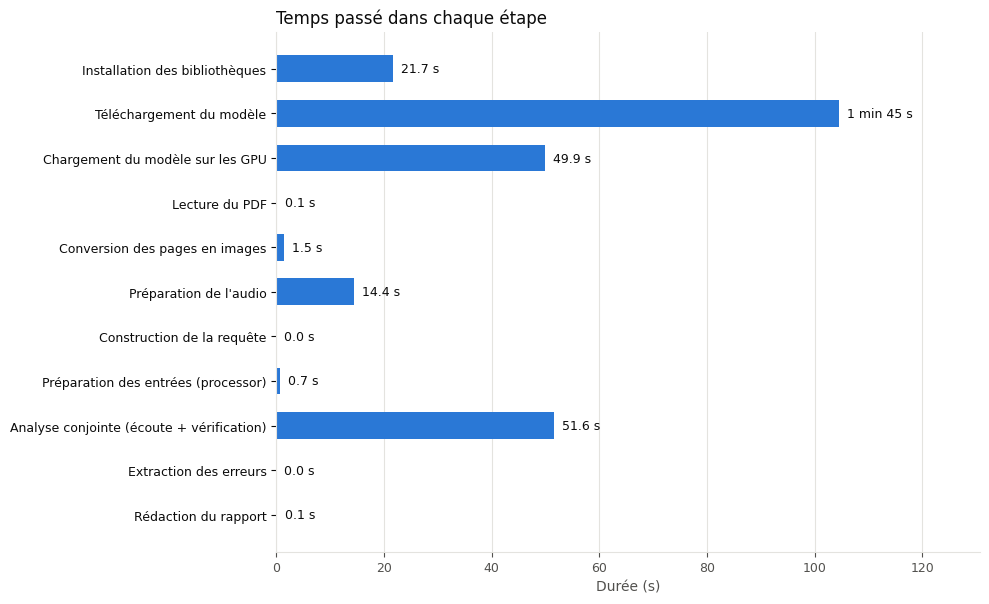

### L'appel au modèle (inférence)

*Lecture de l'entrée = temps jusqu'au premier token (le modèle lit images, audio et texte) ; écriture = production de la réponse, token par token.*

,Inférence,Adaptateur,Tokens entrée (image / audio / texte),Tokens sortie,Durée (s),Lecture de l'entrée (s),Écriture (tokens/s),Mémoire PyTorch pic (Gio) GPU0 / GPU1,Utilisation GPU moy. (%) GPU0 / GPU1,Puissance moy. (W) GPU0 / GPU1,Énergie GPU (Wh)
0,Analyse conjointe (pages + audio),—,11351 (8554 / 394 / 2403),374,51.5,19.6,11.7,10.74 / 9.75,41 / 46,51 / 56,1.528


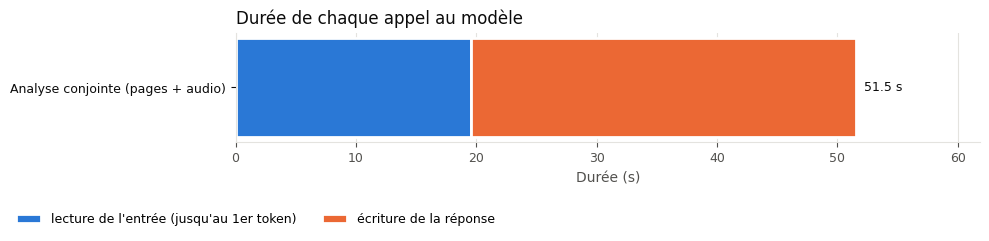

### Ressources GPU au fil du temps

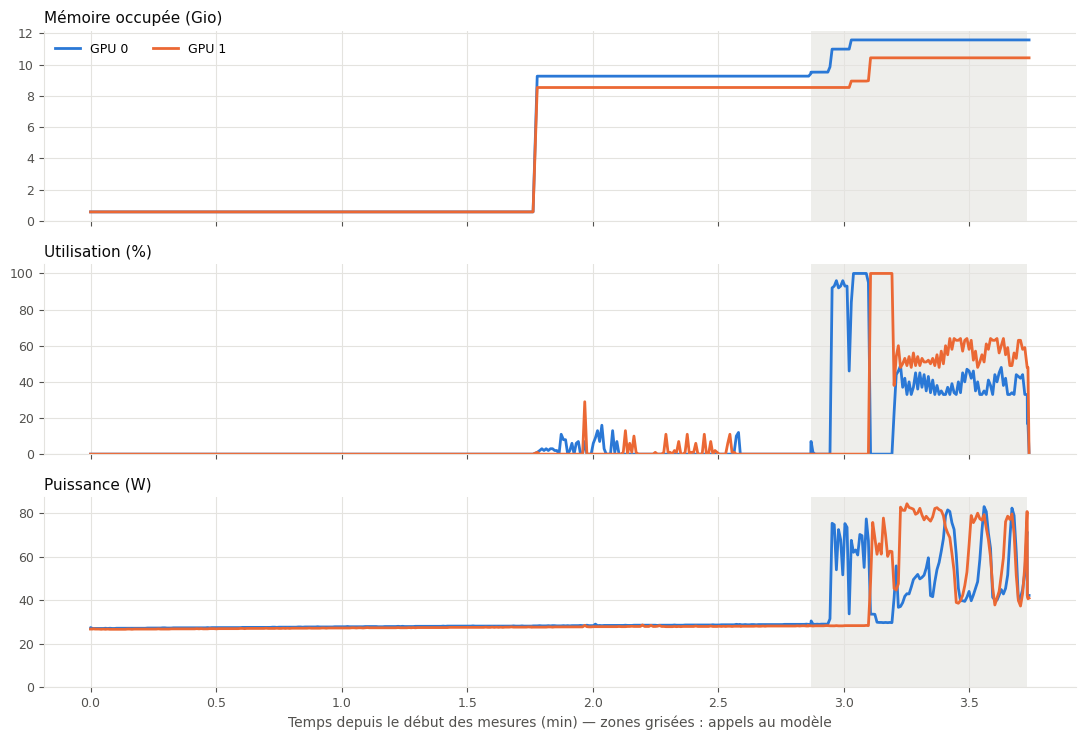

💾 Enregistré dans /kaggle/working/analyse_qwen_omni/resultats : performance.json, performance_etapes.csv, performance_inferences.csv (+ résumé ajouté à rapport_analyse.md)


In [17]:
PERF.fin(afficher=False)          # ferme une étape restée ouverte (cellule interrompue)


def taux_erreur_mots(reference, hypothese):
    """WER = (substitutions + suppressions + insertions) / nombre de mots de la référence (distance d'édition sur les mots)."""
    normaliser = lambda t: re.findall(r"[a-z0-9]+", sans_accents((t or "").lower()))
    ref, hyp = normaliser(reference), normaliser(hypothese)
    d = list(range(len(hyp) + 1))
    for i in range(1, len(ref) + 1):
        precedent, d[0] = d[0], i
        for j in range(1, len(hyp) + 1):
            courant = d[j]
            d[j] = min(d[j] + 1, d[j - 1] + 1, precedent + (ref[i - 1] != hyp[j - 1]))
            precedent = courant
    return d[len(hyp)] / max(len(ref), 1)


ETAPES_INSTALLATION = {"Installation des bibliothèques", "Téléchargement du modèle", "Chargement du modèle sur les GPU"}
ETAPES_DONNEES = {"Lecture du PDF", "Conversion des pages en images", "Préparation de l'audio"}
etapes, inferences = PERF.etapes, PERF.inferences
etapes_analyse = [e for e in etapes if e["etape"] not in ETAPES_INSTALLATION | ETAPES_DONNEES]
m = MESURE_ANALYSE
ENTENDU = " ".join(a["affirmation"] for a in ANALYSE if a["affirmation"])     # ce que Qwen a écrit à l'étape 1
RESUME_PERFORMANCE = {
    "modele": MODEL_ID,
    "duree_totale_notebook_s": sum(e["duree_s"] for e in etapes),
    "duree_analyse_s": sum(e["duree_s"] for e in etapes_analyse),
    "duree_calcul_modele_s": sum(r["duree_s"] for r in inferences),
    "appels_modele": len(inferences),
    "tokens_lus": m["tokens_entree"], "tokens_image": m["tokens_image"], "tokens_audio": m["tokens_audio"],
    "tokens_texte": m["tokens_texte"], "tokens_ecrits": m["tokens_sortie"],
    "lecture_entree_s": m["ttft_s"], "vitesse_lecture_tok_s": m["vitesse_lecture_tok_s"],
    "vitesse_ecriture_moyenne_tok_s": m["vitesse_ecriture_tok_s"],
    "duree_par_affirmation_s": sum(e["duree_s"] for e in etapes_analyse) / max(len(ANALYSE), 1),
    "energie_gpu_totale_wh": sum(e.get("energie_gpu_wh", 0) or 0 for e in etapes),
    "energie_gpu_analyse_wh": sum(e.get("energie_gpu_wh", 0) or 0 for e in etapes_analyse),
    "ram_pic_gio": _maximum([e.get("ram_pic_mo", float("nan")) for e in etapes]) / 1024,
    **{f"gpu{i}_pic_pytorch_gio": _maximum([e.get(f"gpu{i}_pic_pytorch_mo", float("nan")) for e in etapes]) / 1024
       for i in range(PERF.n_gpu)},
    **{f"gpu{i}_pic_occupe_gio": _maximum([e.get(f"gpu{i}_occupe_pic_mo", float("nan")) for e in etapes]) / 1024
       for i in range(PERF.n_gpu)},
    # --- qualité de la sortie (sans vérité de référence) ---
    "affirmations": len(ANALYSE),
    "verdicts_exploitables_pct": 100 * (len(ANALYSE) - len(SANS_VERDICT)) / max(len(ANALYSE), 1),
    "erreurs_detectees": len(ERREURS),
    "analyse_complete": ANALYSE_COMPLETE,
}
if TRANSCRIPTION_REFERENCE:
    RESUME_PERFORMANCE["wer_ecoute_pct"] = 100 * taux_erreur_mots(TRANSCRIPTION_REFERENCE, ENTENDU)

R = RESUME_PERFORMANCE
part_audio = 100 * R["tokens_audio"] / max(R["tokens_lus"], 1)
lignes = [
    ("⏱️ Temps total du notebook", duree_lisible(R["duree_totale_notebook_s"]) + " (installation et téléchargement compris)"),
    ("⏱️ Temps de l'analyse (requête → rapport)", duree_lisible(R["duree_analyse_s"])
     + f" — soit {R['duree_par_affirmation_s']:.1f} s par affirmation"),
    ("🧠 Appel au modèle", f"{R['appels_modele']} requête unique — {R['tokens_lus']} tokens lus (image {R['tokens_image']}, "
                          f"audio {R['tokens_audio']} = {part_audio:.1f} %, texte {R['tokens_texte']}), {R['tokens_ecrits']} tokens écrits"),
    ("📖 Lecture de l'entrée", f"{R['lecture_entree_s']:.1f} s avant le 1er token ({R['vitesse_lecture_tok_s']:.0f} tokens/s)"),
    ("✍️ Écriture", f"{R['vitesse_ecriture_moyenne_tok_s']:.1f} tokens/s"),
    ("💾 Mémoire GPU (pic PyTorch)", " / ".join(f"GPU{i} {R[f'gpu{i}_pic_pytorch_gio']:.1f} Gio" for i in range(PERF.n_gpu))),
    ("💾 Mémoire GPU (pic occupé, pilote)", " / ".join(f"GPU{i} {R[f'gpu{i}_pic_occupe_gio']:.1f} Gio"
                                                      for i in range(PERF.n_gpu))
     + f" sur {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} Gio par GPU"),
    ("🖥️ RAM du notebook (pic)", f"{R['ram_pic_gio']:.1f} Gio"),
    ("⚡ Énergie GPU", f"{R['energie_gpu_totale_wh']:.1f} Wh au total, dont {R['energie_gpu_analyse_wh']:.1f} Wh pour l'analyse"),
    ("✅ Verdicts exploitables", f"{R['verdicts_exploitables_pct']:.0f} % ({len(ANALYSE) - len(SANS_VERDICT)}/{len(ANALYSE)})"),
]
if "wer_ecoute_pct" in R:
    lignes.append(("🎧 Taux d'erreur de mots de l'écoute (WER)", f"{R['wer_ecoute_pct']:.1f} % (0 % = écoute parfaite)"))
display(Markdown("### Résumé\n\n| Mesure | Valeur |\n|---|---|\n" + "\n".join(f"| {a} | {b} |" for a, b in lignes)))

display(Markdown("### Chaque étape du notebook"))
display(PERF.tableau_etapes())
PERF.graphique_etapes()

display(Markdown("### L'appel au modèle (inférence)\n\n*Lecture de l'entrée = temps jusqu'au premier token "
                 "(le modèle lit images, audio et texte) ; écriture = production de la réponse, token par token.*"))
display(PERF.tableau_inferences())
PERF.graphique_inferences()

display(Markdown("### Ressources GPU au fil du temps"))
PERF.graphique_chronologie()

PERF.sauvegarder(DOSSIER_RESULTATS, RESUME_PERFORMANCE)
with open(CHEMIN_RAPPORT, "a", encoding="utf-8") as f:   # le résumé des performances est ajouté au rapport
    f.write("\n\n---\n\n## Performances\n\n| Mesure | Valeur |\n|---|---|\n"
            + "\n".join(f"| {a} | {b} |" for a, b in lignes) + "\n")
print(f"💾 Enregistré dans {DOSSIER_RESULTATS} : performance.json, performance_etapes.csv, performance_inferences.csv "
      "(+ résumé ajouté à rapport_analyse.md)")